# Seattle Airbnb — Exploratory Data Analysis (EDA)

**Course:** DSBA 6156 Applied Machine Learning | Fall 2026  
**Author:** Dzmitry Prybysh  
**Data Source:** Cleaned, integrated Seattle Airbnb datasets generated in Phase D2 (`data/processed/listings_clean.csv` and `data/processed/calendar_clean.csv`).

---

## Notebook Roadmap
This notebook conducts systematic exploratory data analysis (EDA) to investigate market structure, price determinants, spatial variation, calendar dynamics, and guest review patterns, adhering to the project proposal and Week 2 EDA principles.

- **Block 1 (Completed):** Data ingestion with D2.5 type restoration, univariate analysis of listing base price (`price`), and bivariate comparison across accommodation types (`room_type`).
- **Block 2 (Completed):** Spatial variation across 17 neighborhood groups, Walk Score coverage audit (2,733 / 1,085), and neighborhood-level association across 73 matched areas.
- **Block 3 (Completed):** Calendar dynamics, advertised price trajectory, day-of-week patterns, and date category analysis.
- **Block 4 (Completed):** Review counts, guest rating distributions, missingness structure, and host characteristics.
- **Block 5 (Completed):** Summary of key EDA findings and methodological limitations.


## 1. Environment Setup & Data Ingestion

We begin by establishing path configurations, visual formatting defaults, and loading the processed listing-level dataset (`listings_clean.csv`) from `data/processed/`.

In accordance with the **Phase D2.5 Data Export & Type Restoration Protocol**, pandas data types are restored at read time:
- Date fields are parsed via `parse_dates`.
- Binary indicator fields are cast to nullable boolean (`boolean`) via the `dtype` dictionary.
- Nullable integer counts (Walk Score metrics, review aggregates) are loaded as `Int64`.


In [1]:
import os
os.environ["MPLCONFIGDIR"] = "/tmp/matplotlib"
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure pandas display
pd.set_option("display.max_columns", 105)
pd.set_option("display.max_rows", 50)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

# Configure visualization style
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.linewidth"] = 0.8

# Resolve robust project directories
cwd = Path.cwd().resolve()
if cwd.name == "notebooks":
    PROJECT_ROOT = cwd.parent
elif (cwd / "notebooks").exists():
    PROJECT_ROOT = cwd
else:
    candidates = list(cwd.glob("**/seattle-airbnb-ml"))
    PROJECT_ROOT = candidates[0] if candidates else cwd

PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR = PROCESSED_DATA_DIR


In [2]:
# Define explicit type restoration schemas according to Phase D2.5 protocol
DATE_COLS_LISTINGS = [
    'last_scraped', 'host_since', 'calendar_last_scraped',
    'first_review', 'last_review',
    'rev_first_date_from_reviews', 'rev_last_date_from_reviews'
]
BOOL_COLS_LISTINGS = [
    'host_is_superhost', 'host_has_profile_pic', 'host_identity_verified',
    'is_location_exact', 'has_availability', 'requires_license',
    'instant_bookable', 'require_guest_profile_picture', 'require_guest_phone_verification'
]
INT_COLS_LISTINGS = [
    'walk_score', 'transit_score', 'bike_score', 'ws_population', 'ws_rank',
    'rev_count_from_reviews', 'rev_unique_reviewers'
]

dtypes_listings = {col: 'boolean' for col in BOOL_COLS_LISTINGS}
dtypes_listings.update({col: 'Int64' for col in INT_COLS_LISTINGS})

# Load listings_clean.csv
listings_path = PROCESSED_DIR / 'listings_clean.csv'
df_listings = pd.read_csv(
    listings_path,
    parse_dates=DATE_COLS_LISTINGS,
    dtype=dtypes_listings
)

# Baseline structural assertions
assert df_listings.shape == (3818, 102), f"Unexpected shape: {df_listings.shape}"
assert df_listings['id'].is_unique, "Primary key id is not unique"
assert df_listings['id'].notna().all(), "Primary key id contains null values"

print(f"Successfully loaded listings_clean.csv: {df_listings.shape[0]:,} rows × {df_listings.shape[1]} columns.")
print(f"Primary key uniqueness verified (id.is_unique = {df_listings['id'].is_unique}).")
display(df_listings[['id', 'name', 'room_type', 'property_type', 'accommodates', 'price', 'walk_score', 'rev_count_from_reviews']].head(5))

Successfully loaded listings_clean.csv: 3,818 rows × 102 columns.
Primary key uniqueness verified (id.is_unique = True).


,id,name,room_type,property_type,accommodates,price,walk_score,rev_count_from_reviews
0,241032,Stylish Queen Anne Apartment,Entire home/apt,Apartment,4,85.00,84,207
1,953595,Bright & Airy Queen Anne Apartment,Entire home/apt,Apartment,4,150.00,84,43
2,3308979,New Modern House-Amazing water view,Entire home/apt,House,11,975.00,84,20
3,7421966,Queen Anne Chateau,Entire home/apt,Apartment,3,100.00,84,<NA>
4,278830,Charming craftsman 3 bdm house,Entire home/apt,House,6,450.00,84,38


## 2. Univariate Analysis: Listing Base Price (`price`)

Listing base price is an important market characteristic and a potential explanatory variable in analyzing listing performance. In our predictive modeling framework, primary targets focus on listing success dimensions (such as occupancy rate, estimated revenue, and customer review scores), while base price provides essential structural context.

In this section, we examine its central tendency, dispersion, and distributional shape, and compute outlier bounds using the Interquartile Range (IQR) method.


In [3]:
# Compute comprehensive descriptive statistics for listing price
price_series = df_listings['price']

n_obs = len(price_series)
n_missing = price_series.isna().sum()
mean_val = price_series.mean()
std_val = price_series.std()
median_val = price_series.median()
mode_val = price_series.mode()[0]
q25_val = price_series.quantile(0.25)
q75_val = price_series.quantile(0.75)
iqr_val = q75_val - q25_val
min_val = price_series.min()
max_val = price_series.max()
skew_val = price_series.skew()

# IQR method outlier bounds
iqr_upper = q75_val + 1.5 * iqr_val
iqr_lower = q25_val - 1.5 * iqr_val
outliers_upper = (price_series > iqr_upper)
outliers_lower = (price_series < iqr_lower)

price_summary = pd.DataFrame([
    {'Metric': 'Observations (N)', 'Value': f'{n_obs:,}'},
    {'Metric': 'Missing Values', 'Value': f'{n_missing}'},
    {'Metric': 'Mean ($)', 'Value': f'{mean_val:.2f}'},
    {'Metric': 'Median ($)', 'Value': f'{median_val:.2f}'},
    {'Metric': 'Mode ($)', 'Value': f'{mode_val:.2f}'},
    {'Metric': 'Standard Deviation ($)', 'Value': f'{std_val:.2f}'},
    {'Metric': 'Minimum ($)', 'Value': f'{min_val:.2f}'},
    {'Metric': '25th Percentile Q1 ($)', 'Value': f'{q25_val:.2f}'},
    {'Metric': '75th Percentile Q3 ($)', 'Value': f'{q75_val:.2f}'},
    {'Metric': 'Maximum ($)', 'Value': f'{max_val:.2f}'},
    {'Metric': 'Interquartile Range IQR ($)', 'Value': f'{iqr_val:.2f}'},
    {'Metric': 'Skewness', 'Value': f'{skew_val:.2f}'},
    {'Metric': 'Upper IQR Bound (Q3 + 1.5 × IQR) ($)', 'Value': f'{iqr_upper:.2f}'},
    {'Metric': 'Listings Above Upper IQR Bound (N, %)', 'Value': f'{outliers_upper.sum():,} ({outliers_upper.sum()/n_obs*100:.2f}%)'},
    {'Metric': 'Lower IQR Bound (Q1 - 1.5 × IQR) ($)', 'Value': f'{iqr_lower:.2f}'},
    {'Metric': 'Listings Below Lower IQR Bound', 'Value': f'{outliers_lower.sum()}'}
])

display(price_summary)


,Metric,Value
0,Observations (N),"3,818"
1,Missing Values,0
2,Mean ($),127.98
3,Median ($),100.00
4,Mode ($),150.00
5,Standard Deviation ($),90.25
6,Minimum ($),20.00
7,25th Percentile Q1 ($),75.00
8,75th Percentile Q3 ($),150.00
9,Maximum ($),1000.00


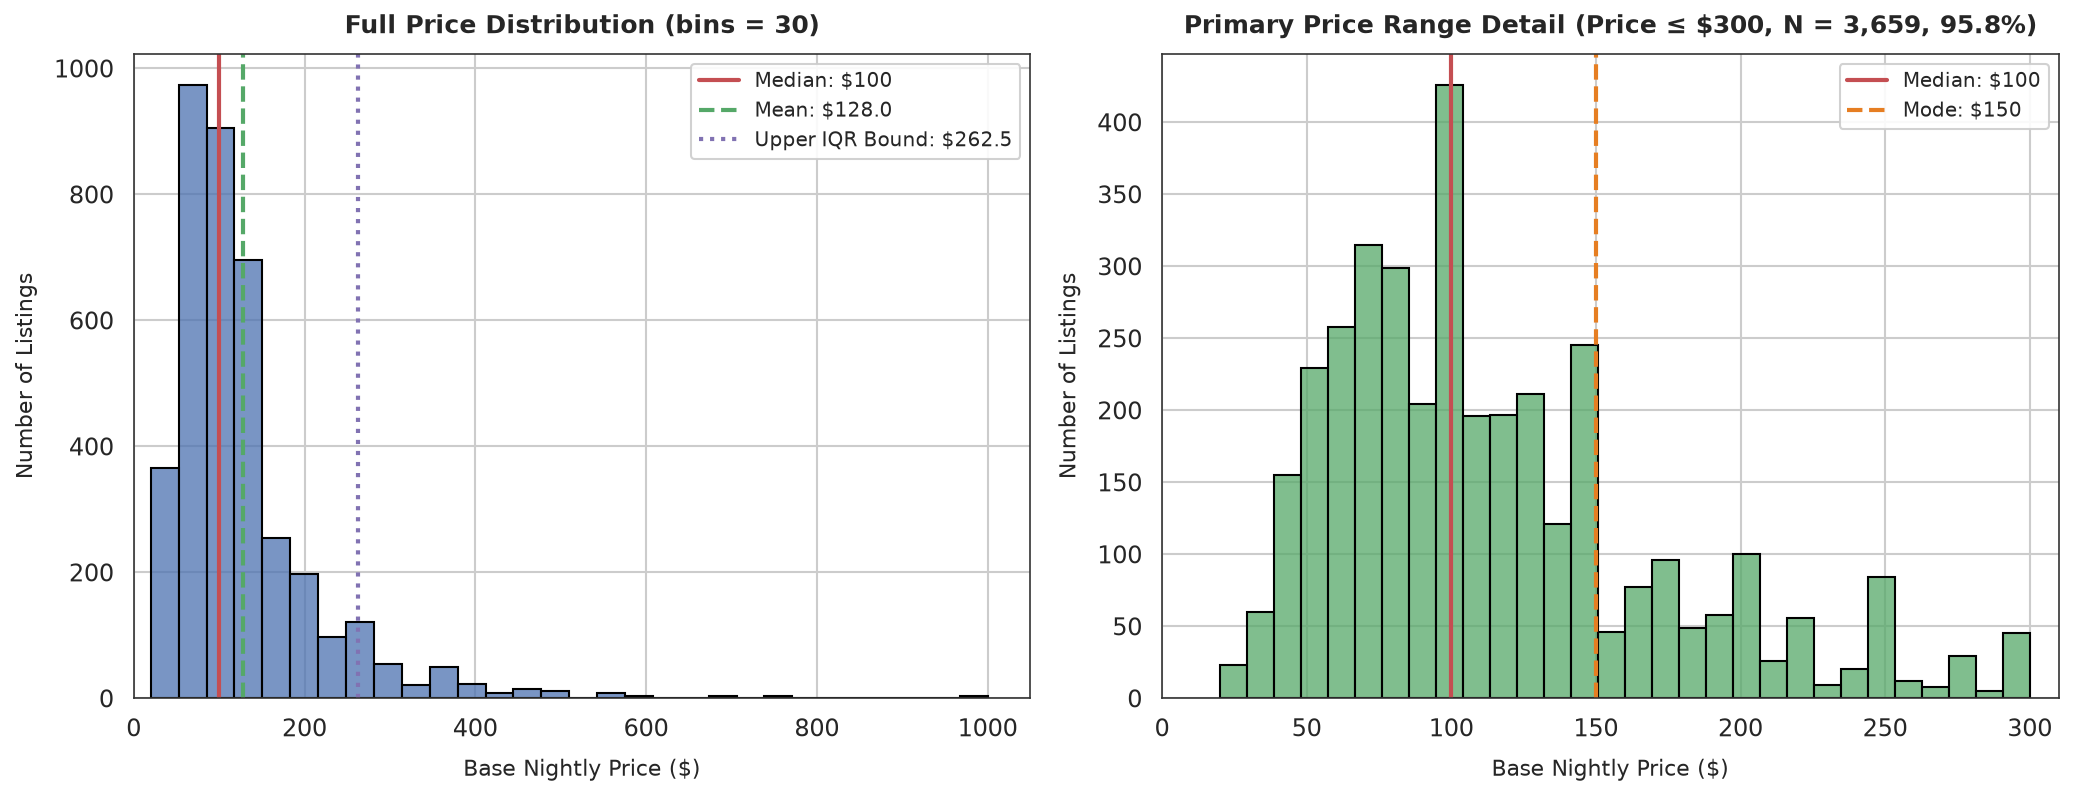

In [4]:
# Plot comprehensive price distribution: full range with 30 bins and focused primary density range
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: Full Range Distribution (30 bins)
sns.histplot(
    price_series,
    bins=30,
    color='#4C72B0',
    edgecolor='black',
    alpha=0.75,
    ax=ax1
)
ax1.axvline(median_val, color='#C44E52', linestyle='-', linewidth=2, label=f'Median: ${median_val:.0f}')
ax1.axvline(mean_val, color='#55A868', linestyle='--', linewidth=2, label=f'Mean: ${mean_val:.1f}')
ax1.axvline(iqr_upper, color='#8172B2', linestyle=':', linewidth=2, label=f'Upper IQR Bound: ${iqr_upper:.1f}')
ax1.set_title('Full Price Distribution (bins = 30)', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('Base Nightly Price ($)', fontsize=10.5, labelpad=8)
ax1.set_ylabel('Number of Listings', fontsize=10.5, labelpad=8)
ax1.set_xlim(0, 1050)
ax1.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=9.5)

# Subplot 2: Detailed Primary Range (Price <= $300, dynamically calculated)
primary_prices = price_series[price_series <= 300]
primary_n = len(primary_prices)
primary_pct = primary_n / len(price_series) * 100

sns.histplot(
    primary_prices,
    bins=30,
    color='#55A868',
    edgecolor='black',
    alpha=0.75,
    ax=ax2
)
ax2.axvline(median_val, color='#C44E52', linestyle='-', linewidth=2, label=f'Median: ${median_val:.0f}')
ax2.axvline(mode_val, color='#E67E22', linestyle='--', linewidth=2, label=f'Mode: ${mode_val:.0f}')
ax2.set_title(f'Primary Price Range Detail (Price ≤ $300, N = {primary_n:,}, {primary_pct:.1f}%)', fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel('Base Nightly Price ($)', fontsize=10.5, labelpad=8)
ax2.set_ylabel('Number of Listings', fontsize=10.5, labelpad=8)
ax2.set_xlim(0, 310)
ax2.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=9.5)

plt.tight_layout()
plt.show()


### 2.2 Factual Findings on Price Distribution

1. **Central Tendency & Asymmetry:**
   - The sample median price is **$100.00**, while the sample mean is **$127.98**.
   - The distribution exhibits pronounced positive right-skewness (**skewness = +3.11**), characterized by a heavy right tail extending to **$1,000.00**.
   - The most frequent exact price (mode) is **$150.00**.

2. **Spread & Dispersion:**
   - 50% of all listings fall within the interquartile range of **$75.00** ($Q_1$) to **$150.00** ($Q_3$), yielding an $IQR$ of **$75.00**.
   - The minimum observed price is **$20.00**, and the standard deviation is **$90.25**.
   - Focusing on the primary price range ($\le \$300$), which encompasses **3,659 listings (95.84% of the dataset)**, reveals distinct clustering around common pricing increments ($50, $75, $100, $150, $200). (By comparison, the upper IQR bound of **$262.50** captures **3,572 listings (93.56%)**, with **87 listings** situated in the interval between $262.50 and $300.00).

3. **Description of Values Outside IQR Bounds:**
   - Applying the IQR method ($Q_3 + 1.5 \times IQR$) yields a calculated upper IQR bound of **$262.50** (while the upper whisker in our data ends at **$260.00**, the highest observed value not exceeding this bound).
   - Exactly **246 listings (6.44% of the dataset)** lie above this upper IQR bound.
   - The lower IQR bound ($Q_1 - 1.5 \times IQR = -\$37.50$) lies below zero; no listings fall below the lower bound.
   - **Handling of Upper-Tail Observations:** All 3,818 observations are retained in the dataset without truncation or removal. Higher prices may reflect differences in capacity, location, or amenities. Further analysis is needed to distinguish legitimate premium listings from potential data issues.
   - **Consideration of Variable Transformations:** A logarithmic transformation ($\log(\text{price})$) may be considered as a potential option during feature preprocessing (for instance, to stabilize variance or model proportional effects), subject to empirical evaluation during subsequent modeling steps.


## 3. Bivariate Analysis: Price across Room Types (`room_type`)

Listing accommodations in the dataset are classified into three distinct categories: `Entire home/apt`, `Private room`, and `Shared room`. 

We examine how price distributions vary across these categories, computing group-level sample sizes, central tendencies, spreads, and group-specific outlier boundaries.

In [5]:
# Compute detailed price distribution metrics grouped by room_type
room_type_stats = []

for rt_name, grp in df_listings.groupby('room_type', observed=True):
    p = grp['price']
    n_grp = len(p)
    q25_grp = p.quantile(0.25)
    q75_grp = p.quantile(0.75)
    iqr_grp = q75_grp - q25_grp
    iqr_upper_grp = q75_grp + 1.5 * iqr_grp
    iqr_lower_grp = q25_grp - 1.5 * iqr_grp
    outliers_grp = (p > iqr_upper_grp).sum()
    
    room_type_stats.append({
        'Room Type': rt_name,
        'Listing Count (N)': n_grp,
        'Share of Sample (%)': (n_grp / len(df_listings)) * 100,
        'Mean ($)': p.mean(),
        'Standard Deviation ($)': p.std(),
        'Minimum ($)': p.min(),
        'Q1 ($)': q25_grp,
        'Median ($)': p.median(),
        'Q3 ($)': q75_grp,
        'Maximum ($)': p.max(),
        'IQR ($)': iqr_grp,
        'Upper IQR Bound ($)': iqr_upper_grp,
        'Outliers Count (N)': outliers_grp,
        'Outliers Share (%)': (outliers_grp / n_grp) * 100
    })

df_room_type_summary = pd.DataFrame(room_type_stats)
# Sort by count descending
df_room_type_summary = df_room_type_summary.sort_values(by='Listing Count (N)', ascending=False).reset_index(drop=True)

# Format for clean display
display_table = df_room_type_summary.copy()
display_table['Listing Count (N)'] = display_table['Listing Count (N)'].map(lambda x: f'{x:,}')
display_table['Share of Sample (%)'] = display_table['Share of Sample (%)'].map(lambda x: f'{x:.2f}%')
display_table['Mean ($)'] = display_table['Mean ($)'].map(lambda x: f'${x:.2f}')
display_table['Standard Deviation ($)'] = display_table['Standard Deviation ($)'].map(lambda x: f'${x:.2f}')
display_table['Minimum ($)'] = display_table['Minimum ($)'].map(lambda x: f'${x:.2f}')
display_table['Q1 ($)'] = display_table['Q1 ($)'].map(lambda x: f'${x:.2f}')
display_table['Median ($)'] = display_table['Median ($)'].map(lambda x: f'${x:.2f}')
display_table['Q3 ($)'] = display_table['Q3 ($)'].map(lambda x: f'${x:.2f}')
display_table['Maximum ($)'] = display_table['Maximum ($)'].map(lambda x: f'${x:.2f}')
display_table['IQR ($)'] = display_table['IQR ($)'].map(lambda x: f'${x:.2f}')
display_table['Upper IQR Bound ($)'] = display_table['Upper IQR Bound ($)'].map(lambda x: f'${x:.2f}')
display_table['Outliers Count (N)'] = display_table['Outliers Count (N)'].map(lambda x: f'{x:,}')
display_table['Outliers Share (%)'] = display_table['Outliers Share (%)'].map(lambda x: f'{x:.2f}%')

display(display_table)


,Room Type,Listing Count (N),Share of Sample (%),Mean ($),Standard Deviation ($),Minimum ($),Q1 ($),Median ($),Q3 ($),Maximum ($),IQR ($),Upper IQR Bound ($),Outliers Count (N),Outliers Share (%)
0,Entire home/apt,"2,541",66.55%,$155.84,$96.55,$39.00,$99.00,$126.00,$179.00,$1000.00,$80.00,$299.00,186,7.32%
1,Private room,"1,160",30.38%,$75.04,$34.60,$20.00,$55.00,$69.00,$87.00,$399.00,$32.00,$135.00,61,5.26%
2,Shared room,117,3.06%,$47.55,$19.37,$22.00,$35.00,$40.00,$55.00,$118.00,$20.00,$85.00,8,6.84%


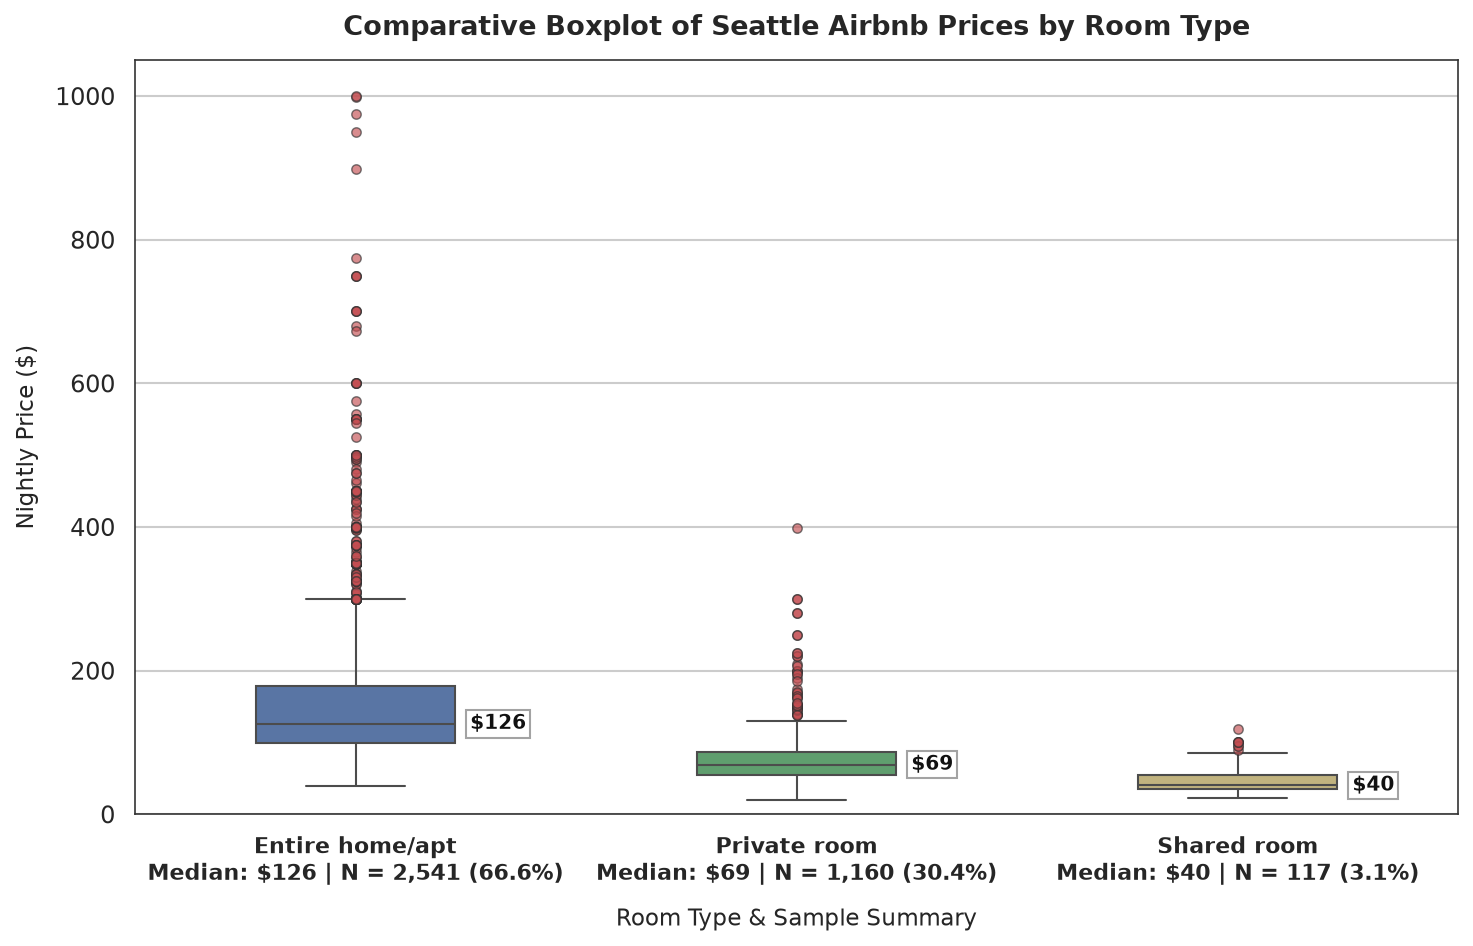

In [6]:
# Plot comparative boxplot of prices across room_type with distinct outliers and clear labels
fig, ax = plt.subplots(figsize=(10, 6.5))

room_order = ['Entire home/apt', 'Private room', 'Shared room']
palette_colors = {'Entire home/apt': '#4C72B0', 'Private room': '#55A868', 'Shared room': '#CCB974'}

medians = df_listings.groupby('room_type')['price'].median()
counts = df_listings.groupby('room_type')['price'].count()

sns.boxplot(
    data=df_listings,
    x='room_type',
    y='price',
    order=room_order,
    hue='room_type',
    palette=palette_colors,
    legend=False,
    width=0.45,
    fliersize=4.5,
    flierprops=dict(
        marker='o',
        markerfacecolor='#C44E52',
        markeredgecolor='#333333',
        markeredgewidth=0.7,
        alpha=0.65
    ),
    ax=ax
)

# Put clear, non-overlapping labels on the X-axis ticks
xtick_labels = [
    f"{rt}\nMedian: ${medians[rt]:.0f} | N = {counts[rt]:,} ({counts[rt]/len(df_listings)*100:.1f}%)"
    for rt in room_order
]
ax.set_xticks(range(len(room_order)))
ax.set_xticklabels(xtick_labels, fontsize=10.5, fontweight='bold')

# Add median value tags offset to the right of each box to avoid visual overlap
for i, rt in enumerate(room_order):
    med = medians[rt]
    ax.annotate(
        f"${med:.0f}",
        xy=(i, med),
        xytext=(i + 0.26, med),
        va='center',
        fontsize=9.5,
        fontweight='bold',
        color='#111111',
        bbox=dict(boxstyle='square,pad=0.2', facecolor='white', edgecolor='#999999', alpha=0.9)
    )

ax.set_title('Comparative Boxplot of Seattle Airbnb Prices by Room Type', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Room Type & Sample Summary', fontsize=11, labelpad=10)
ax.set_ylabel('Nightly Price ($)', fontsize=11, labelpad=8)
ax.set_ylim(0, 1050)

plt.tight_layout()
plt.show()


### 3.2 Factual Findings & Room Type Comparison

1. **Sample Composition & Listing Counts:**
   - **`Entire home/apt`** represents the majority of listings in our sample, accounting for **2,541 listings (66.55%)**.
   - **`Private room`** constitutes nearly one-third of listings in our sample with **1,160 listings (30.38%)**.
   - **`Shared room`** is a minor category comprising **117 listings (3.06%)**.

2. **Price Levels by Accommodation Category:**
   - **`Entire home/apt`:** Exhibits the highest central price level with a **median of $126.00** and a mean of **$155.84**. It displays the greatest dispersion ($IQR = \$80.00$, range from $\$39.00$ to $\$1,000.00$, standard deviation of $\$96.55$).
   - **`Private room`:** Occupies a substantially lower price band with a **median of $69.00** and a mean of **$75.04**. The dispersion is considerably tighter ($IQR = \$32.00$, standard deviation of $\$34.60$, spanning from $\$20.00$ to $\$399.00$).
   - **`Shared room`:** Represents the lowest price tier with a **median of $40.00** and a mean of **$47.55**. Prices are tightly clustered ($IQR = \$20.00$, standard deviation of $\$19.37$, ranging from $\$22.00$ to $\$118.00$).

3. **Analysis of Observations Outside Category IQR Bounds:**
   - Category-specific upper IQR bounds ($Q_3 + 1.5 \times IQR$) differ markedly:
     - `Entire home/apt`: upper IQR bound is **$299.00** (upper whisker ends at **$299.00**); **186 listings (7.32%)** lie above this bound.
     - `Private room`: upper IQR bound is **$135.00** (upper whisker ends at **$130.00**); **61 listings (5.26%)** lie above this bound.
     - `Shared room`: upper IQR bound is **$85.00** (upper whisker ends at **$85.00**); **8 listings (6.84%)** lie above this bound.
   - Across all three categories, no listings fall below the category lower IQR bounds.
   - **Analytical Treatment:** All observations outside the category IQR bounds are preserved. Higher prices within each room category may reflect differences in capacity, location, or amenities. Further analysis is needed to distinguish legitimate premium listings from potential data issues.


## 4. Spatial Variation across Neighborhood Groups & Walk Score Analysis

In this section, we examine the geographic dimension of the Seattle Airbnb market and explore the external Walk Score mobility metrics integrated during Phase D2:
1. **Neighborhood Groups (`neighbourhood_group_cleansed`):** We compute listing counts, sample proportions, and descriptive statistics (Median, $Q_1$, $Q_3$, $IQR$) across all 17 aggregate municipal districts, visualizing the distribution via a horizontal boxplot.
2. **Walk Score Coverage Structure:** We profile the exact coverage of Walk Score metrics across the 17 groups, documenting the distribution of the **2,733 matched listings** and **1,085 missing listings**.
3. **Neighborhood-Level Association (73 matched areas):** We aggregate data to the individual neighborhood level (`neighbourhood_cleansed`) across the 73 matched areas, computing the Pearson correlation coefficient at the neighborhood level between Walk Score and median price, and visualizing the relationship with a scatter plot.


In [7]:
# 1. Compute summary statistics across 17 aggregate neighbourhood groups
grp_stats = []

for grp_name, g in df_listings.groupby('neighbourhood_group_cleansed', observed=True):
    p = g['price']
    n_cnt = len(p)
    q25 = p.quantile(0.25)
    q75 = p.quantile(0.75)
    iqr = q75 - q25
    med = p.median()
    
    grp_stats.append({
        'Neighbourhood Group': grp_name,
        'Listing Count (N)': n_cnt,
        'Share of Sample (%)': (n_cnt / len(df_listings)) * 100,
        'Median ($)': med,
        'Q1 ($)': q25,
        'Q3 ($)': q75,
        'IQR ($)': iqr
    })

df_neighbourhood_groups = pd.DataFrame(grp_stats)
# Sort by Median descending
df_neighbourhood_groups = df_neighbourhood_groups.sort_values(by='Median ($)', ascending=False).reset_index(drop=True)

# Format for display
display_groups = df_neighbourhood_groups.copy()
display_groups['Listing Count (N)'] = display_groups['Listing Count (N)'].map(lambda x: f'{x:,}')
display_groups['Share of Sample (%)'] = display_groups['Share of Sample (%)'].map(lambda x: f'{x:.2f}%')
display_groups['Median ($)'] = display_groups['Median ($)'].map(lambda x: f'${x:.2f}')
display_groups['Q1 ($)'] = display_groups['Q1 ($)'].map(lambda x: f'${x:.2f}')
display_groups['Q3 ($)'] = display_groups['Q3 ($)'].map(lambda x: f'${x:.2f}')
display_groups['IQR ($)'] = display_groups['IQR ($)'].map(lambda x: f'${x:.2f}')

display(display_groups)


,Neighbourhood Group,Listing Count (N),Share of Sample (%),Median ($),Q1 ($),Q3 ($),IQR ($)
0,Downtown,530,13.88%,$139.00,$105.00,$175.00,$70.00
1,Magnolia,61,1.60%,$129.00,$78.00,$225.00,$147.00
2,Queen Anne,295,7.73%,$119.00,$95.00,$175.00,$80.00
3,Cascade,89,2.33%,$115.00,$88.00,$141.00,$53.00
4,West Seattle,203,5.32%,$109.00,$79.00,$195.00,$116.00
5,Capitol Hill,567,14.85%,$105.00,$80.00,$150.00,$70.00
6,Central Area,369,9.66%,$100.00,$75.00,$155.00,$80.00
7,Other neighborhoods,794,20.80%,$99.00,$66.00,$145.00,$79.00
8,Ballard,230,6.02%,$95.00,$70.00,$149.00,$79.00
9,Seward Park,44,1.15%,$93.00,$65.00,$118.00,$53.00


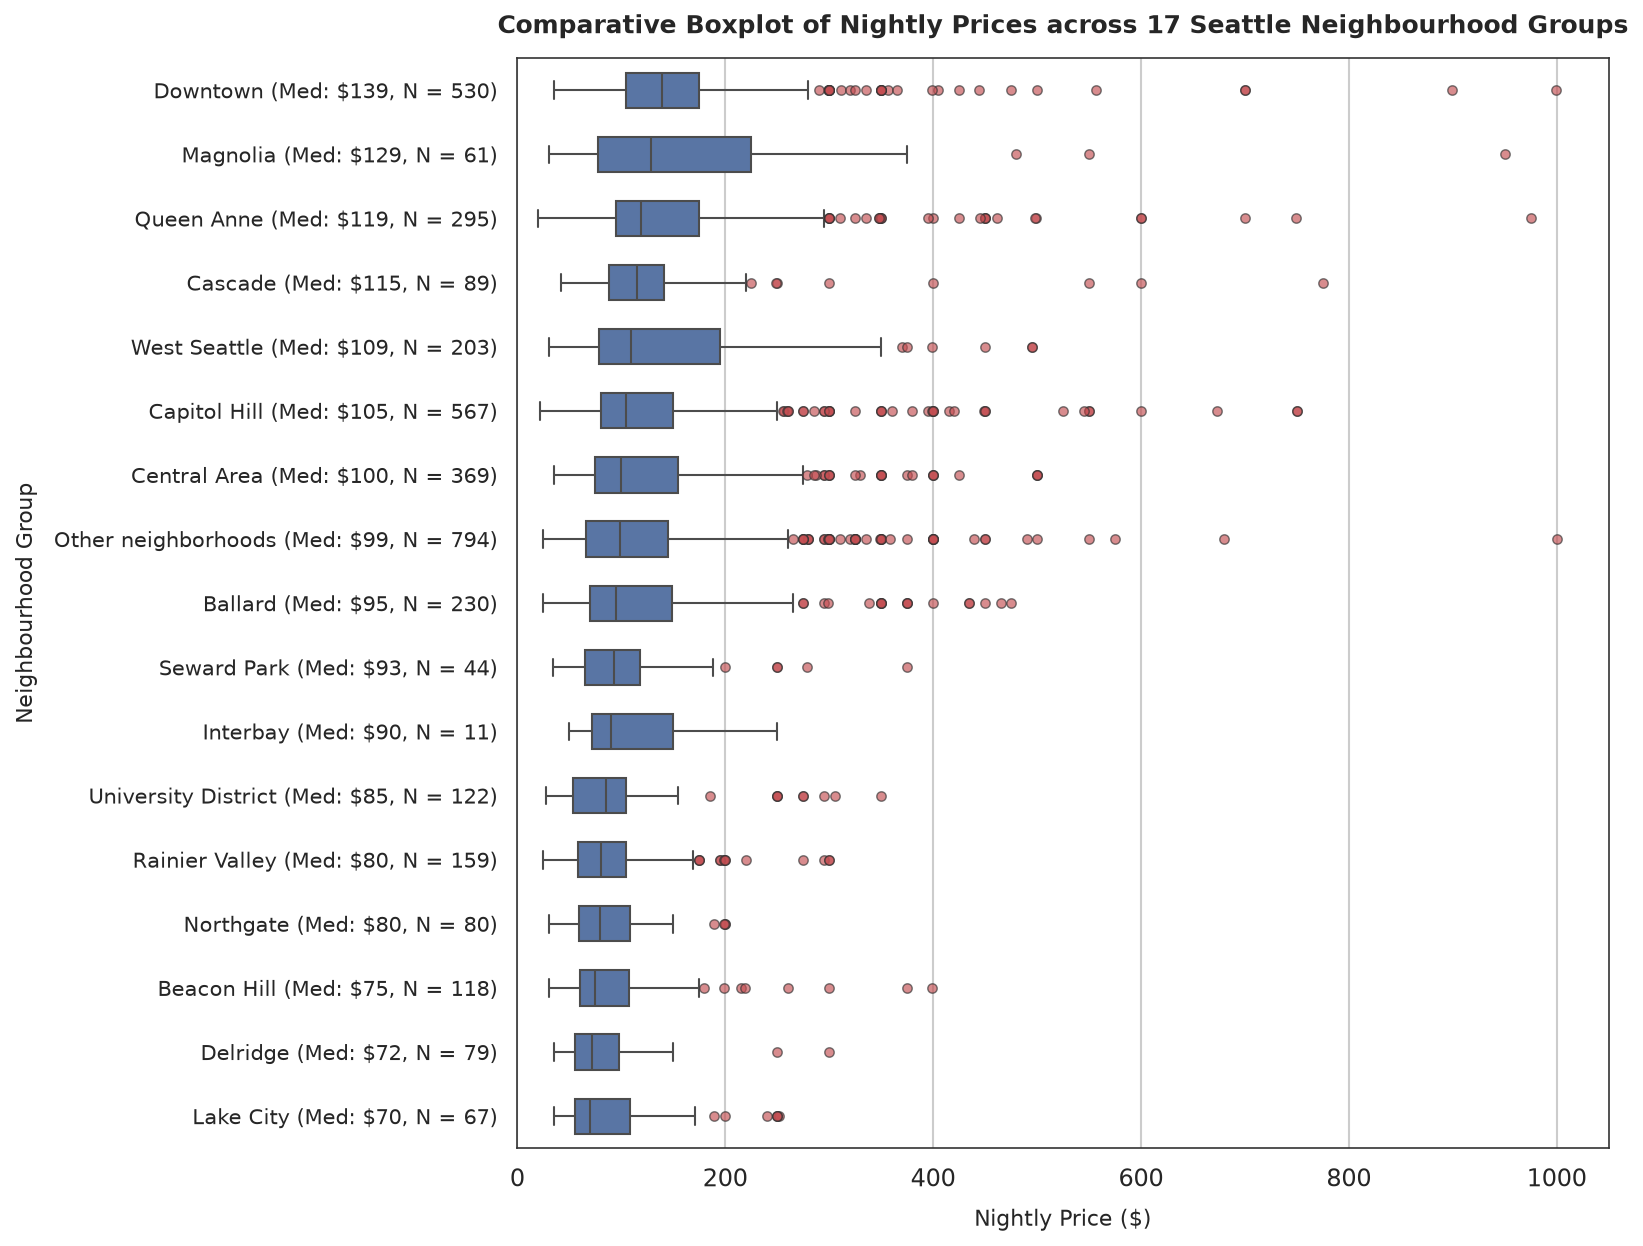

In [8]:
# Plot comparative horizontal boxplot across 17 neighbourhood groups
group_order = list(df_neighbourhood_groups['Neighbourhood Group'])
group_medians = dict(zip(df_neighbourhood_groups['Neighbourhood Group'], df_neighbourhood_groups['Median ($)']))
group_counts = dict(zip(df_neighbourhood_groups['Neighbourhood Group'], df_neighbourhood_groups['Listing Count (N)']))

fig, ax = plt.subplots(figsize=(11, 8.5))

sns.boxplot(
    data=df_listings,
    y='neighbourhood_group_cleansed',
    x='price',
    order=group_order,
    color='#4C72B0',
    width=0.55,
    fliersize=4.5,
    flierprops=dict(
        marker='o',
        markerfacecolor='#C44E52',
        markeredgecolor='#333333',
        markeredgewidth=0.7,
        alpha=0.65
    ),
    ax=ax
)

# Label y-ticks with Group Name, Median Price, and Sample Size
ytick_labels = [
    f"{grp} (Med: ${group_medians[grp]:.0f}, N = {group_counts[grp]:,})"
    for grp in group_order
]
ax.set_yticks(range(len(group_order)))
ax.set_yticklabels(ytick_labels, fontsize=10)

ax.set_title('Comparative Boxplot of Nightly Prices across 17 Seattle Neighbourhood Groups', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Nightly Price ($)', fontsize=10.5, labelpad=8)
ax.set_ylabel('Neighbourhood Group', fontsize=10.5, labelpad=8)
ax.set_xlim(0, 1050)

plt.tight_layout()
plt.show()


### 4.2 Factual Findings on Neighborhood Group Price Distributions

1. **Sample Distribution across 17 Neighborhood Groups:**
   - The three largest groups by listing count in our sample are:
     - **`Other neighborhoods`**: **794 listings (20.80%)**;
     - **`Capitol Hill`**: **567 listings (14.85%)**;
     - **`Downtown`**: **530 listings (13.88%)**.
   - Together, these three groups account for nearly half (**49.53%**) of all listings in our sample.
   - The smallest groups by listing count are **`Interbay`** (**11 listings, 0.29%**), **`Seward Park`** (**44 listings, 1.15%**), and **`Magnolia`** (**61 listings, 1.60%**).

2. **Median Price Differences across Groups:**
   - Across the 17 groups, median nightly prices range from **$70.00** to **$139.00**:
     - The highest median prices are observed in **`Downtown`** (**$139.00**, $IQR = \$70.00$), **`Magnolia`** (**$129.00**, $IQR = \$147.00$), and **`Queen Anne`** (**$119.00**, $IQR = \$80.00$).
     - Intermediate medians include **`Cascade`** (**$115.00**), **`West Seattle`** (**$109.00**), **`Capitol Hill`** (**$105.00**), and **`Central Area`** (**$100.00**).
     - The lowest median prices are observed in **`Delridge`** (**$72.00**, $IQR = \$43.00$) and **`Lake City`** (**$70.00**, $IQR = \$53.00$).
   - All 3,818 observations are preserved in the analysis. Across multiple groups (e.g., Downtown, Queen Anne, Magnolia), boxplot whiskers extend to the highest observed prices within the group IQR bounds, while observations above the group upper IQR bounds are plotted beyond the whiskers and remain in the dataset.


In [9]:
# 2. Walk Score coverage breakdown across 17 neighbourhood groups
coverage_rows = []

for grp_name, g in df_listings.groupby('neighbourhood_group_cleansed', observed=True):
    tot = len(g)
    has_ws = g['walk_score'].notna().sum()
    no_ws = g['walk_score'].isna().sum()
    pct = (has_ws / tot) * 100
    
    coverage_rows.append({
        'Neighbourhood Group': grp_name,
        'Total Listings (N)': tot,
        'With Walk Score (N)': has_ws,
        'Without Walk Score (N)': no_ws,
        'Coverage (%)': pct
    })

df_ws_coverage = pd.DataFrame(coverage_rows).sort_values(by='Total Listings (N)', ascending=False).reset_index(drop=True)

# Add overall sample summary total row
total_matched = df_listings['walk_score'].notna().sum()
total_missing = df_listings['walk_score'].isna().sum()
overall_row = pd.DataFrame([{
    'Neighbourhood Group': 'Total / Overall Sample',
    'Total Listings (N)': len(df_listings),
    'With Walk Score (N)': total_matched,
    'Without Walk Score (N)': total_missing,
    'Coverage (%)': (total_matched / len(df_listings)) * 100
}])

df_ws_coverage_display = pd.concat([df_ws_coverage, overall_row], ignore_index=True)

# Format for clean display
display_cov = df_ws_coverage_display.copy()
display_cov['Total Listings (N)'] = display_cov['Total Listings (N)'].map(lambda x: f'{x:,}')
display_cov['With Walk Score (N)'] = display_cov['With Walk Score (N)'].map(lambda x: f'{x:,}')
display_cov['Without Walk Score (N)'] = display_cov['Without Walk Score (N)'].map(lambda x: f'{x:,}')
display_cov['Coverage (%)'] = display_cov['Coverage (%)'].map(lambda x: f'{x:.2f}%')

display(display_cov)


,Neighbourhood Group,Total Listings (N),With Walk Score (N),Without Walk Score (N),Coverage (%)
0,Other neighborhoods,794,762,32,95.97%
1,Capitol Hill,567,51,516,8.99%
2,Downtown,530,399,131,75.28%
3,Central Area,369,153,216,41.46%
4,Queen Anne,295,295,0,100.00%
5,Ballard,230,96,134,41.74%
6,West Seattle,203,161,42,79.31%
7,Rainier Valley,159,159,0,100.00%
8,University District,122,122,0,100.00%
9,Beacon Hill,118,112,6,94.92%


In [10]:
# 3. Compile table across 73 matched cleansed neighbourhoods
ws_matched_listings = df_listings[df_listings['walk_score'].notna()]

df_hood_73 = ws_matched_listings.groupby('neighbourhood_cleansed').agg(
    neighbourhood_group=('neighbourhood_group_cleansed', 'first'),
    listing_count=('id', 'count'),
    walk_score=('walk_score', 'first'),
    median_price=('price', 'median')
).reset_index()

# Sort by Walk Score descending, then by listing count descending
df_hood_73 = df_hood_73.sort_values(by=['walk_score', 'listing_count'], ascending=[False, False]).reset_index(drop=True)

# Format display table
display_hood_73 = df_hood_73.copy()
display_hood_73.columns = ['Neighbourhood (cleansed)', 'Neighbourhood Group', 'Listing Count (N)', 'Walk Score', 'Median Price ($)']
display_hood_73['Listing Count (N)'] = display_hood_73['Listing Count (N)'].map(lambda x: f'{x:,}')
display_hood_73['Walk Score'] = display_hood_73['Walk Score'].map(lambda x: f'{x:.0f}')
display_hood_73['Median Price ($)'] = display_hood_73['Median Price ($)'].map(lambda x: f'${x:.2f}')

print(f"Summary of Matched Cleansed Neighbourhoods: {len(df_hood_73)} areas covering {len(ws_matched_listings):,} listings.")
display(display_hood_73)


Summary of Matched Cleansed Neighbourhoods: 73 areas covering 2,733 listings.


,Neighbourhood (cleansed),Neighbourhood Group,Listing Count (N),Walk Score,Median Price ($)
0,Belltown,Downtown,234,98,$139.00
1,First Hill,Downtown,108,98,$127.00
2,International District,Downtown,17,98,$80.00
3,Pioneer Square,Downtown,23,97,$150.00
4,South Lake Union,Cascade,27,94,$110.00
5,Yesler Terrace,Downtown,17,94,$112.00
6,University District,University District,122,93,$85.00
7,Lower Queen Anne,Queen Anne,94,92,$119.00
8,Fremont,Other neighborhoods,158,90,$106.00
9,Atlantic,Central Area,53,86,$95.00


Pearson correlation at the neighborhood level (73 neighborhoods): r = 0.1962 (weak positive association).


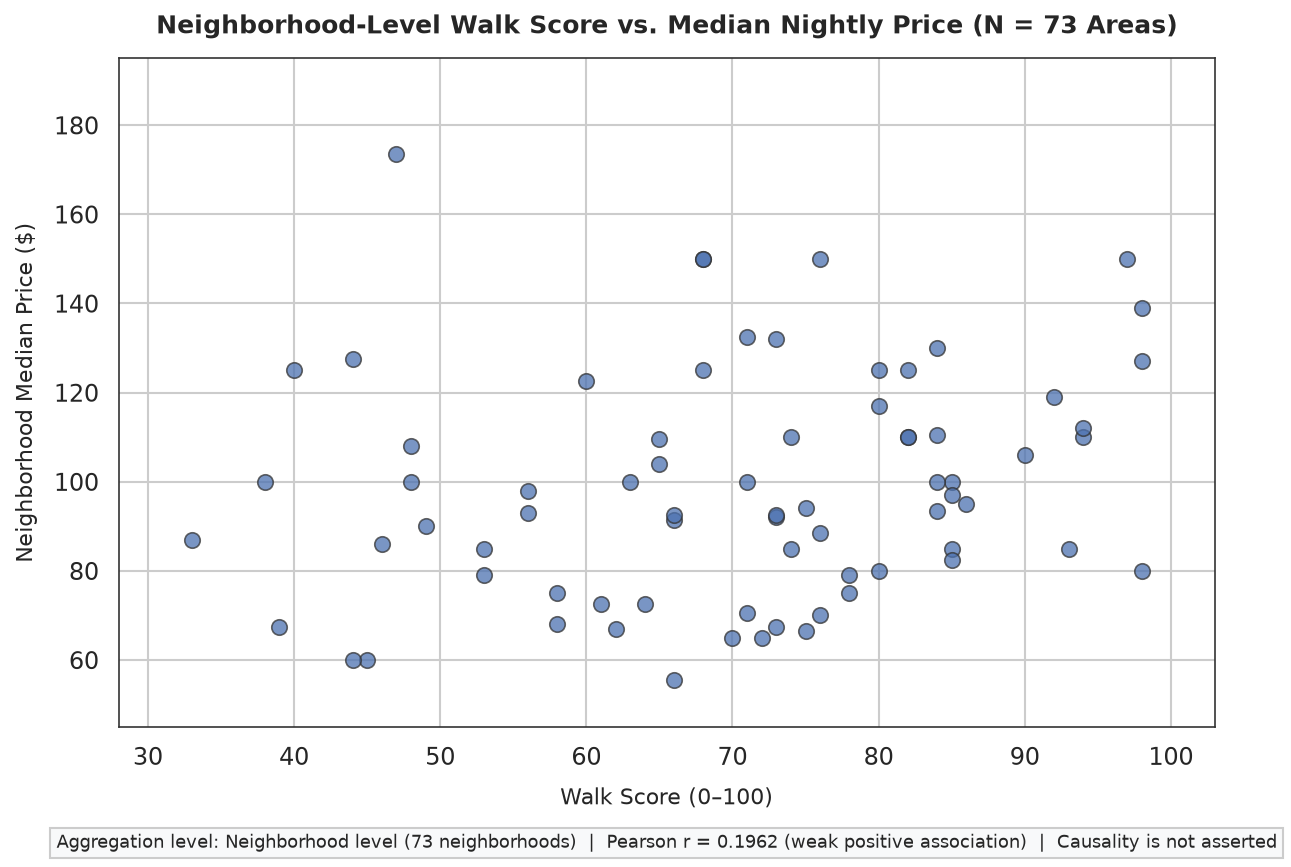

In [11]:
# 4. Scatter plot with one point per neighbourhood (73 points) and Pearson correlation
r_pearson = df_hood_73['walk_score'].astype(float).corr(df_hood_73['median_price'])

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    df_hood_73['walk_score'],
    df_hood_73['median_price'],
    s=55,
    c='#4C72B0',
    alpha=0.75,
    edgecolors='#333333',
    linewidth=0.8
)

ax.set_title('Neighborhood-Level Walk Score vs. Median Nightly Price (N = 73 Areas)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Walk Score (0–100)', fontsize=10.5, labelpad=8)
ax.set_ylabel('Neighborhood Median Price ($)', fontsize=10.5, labelpad=8)
ax.set_xlim(28, 103)
ax.set_ylim(45, 195)

# Caption placed underneath the plot to avoid overlapping points
ax.annotate(
    f"Aggregation level: Neighborhood level (73 neighborhoods)  |  Pearson r = {r_pearson:.4f} (weak positive association)  |  Causality is not asserted",
    xy=(0.5, -0.16),
    xycoords='axes fraction',
    ha='center',
    va='top',
    fontsize=8.5,
    bbox=dict(boxstyle='square,pad=0.35', facecolor='#F8F9FA', edgecolor='#CCCCCC')
)

plt.tight_layout()
plt.show()

print(f"Pearson correlation at the neighborhood level (73 neighborhoods): r = {r_pearson:.4f} (weak positive association).")


### 4.4 Factual Findings on Walk Score Coverage & Neighborhood Price Relationship

1. **Walk Score Coverage Structure (2,733 Matched / 1,085 Missing):**
   - Out of 3,818 listings in the dataset, **2,733 listings (71.58%)** matched external Walk Score records across **73 distinct cleansed neighborhoods**, while **1,085 listings (28.42%)** lack Walk Score metrics across **14 neighborhoods**.
   - Exactly **9 neighborhood groups** have 100% Walk Score coverage in our sample: **Queen Anne**, **Rainier Valley**, **University District**, **Cascade**, **Northgate**, **Delridge**, **Magnolia**, **Seward Park**, and **Interbay**.
   - Groups with lower coverage reflect discrepancies between Airbnb cleansed neighborhood names and the external table, most notably **`Capitol Hill`** (only **51 of 567 listings covered, 8.99%**) and **`Central Area`** (**153 of 369 listings covered, 41.46%**).

2. **Pearson Correlation at the Neighborhood Level (73 Matched Neighborhoods):**
   - Across the 73 matched neighborhoods, there is a weak positive linear association between Walk Score and median price (**Pearson $r = 0.1962$**).
   - Walk Scores in these neighborhoods range from **33** (Matthews Beach) to **98** (Belltown, First Hill, International District), while neighborhood median prices range from **$55.50** (Olympic Hills) to **$173.50** (Southeast Magnolia).
   - **Methodological Scope & Causality:** This calculation evaluates Pearson correlation at the neighborhood level between aggregated neighborhood measures and does not establish causality. It does not describe price relationships at the level of individual listings.


## 5. Calendar Dynamics & Prospective Variations

In this section, we examine the temporal dimension of the Seattle Airbnb market using the prospective calendar dataset (`data/processed/calendar_clean.csv`):
1. **Nature of the Data:** The calendar dataset consists of **1,393,570 listing-days** spanning a 365-day forward horizon (from **January 4, 2016** through **January 2, 2017**). This dataset represents a **prospective snapshot** of advertised prices and host-specified availability as recorded on January 4, 2016, rather than historical realized booking transactions or occupancy over the year. Consequently, our analysis evaluates calendar variations in advertised listings without asserting realized demand growth or proven seasonal causality.
2. **Price vs. Availability Scope:** Nightly prices are observed only when a listing is marked available (`available == True`, 934,542 rows); unavailable dates (`available == False`, 459,028 rows) have missing price values. All price metrics (mean, median) are strictly calculated across available dates only, whereas unavailable shares (%) are calculated across all listing-days within the respective grouping.
3. **Boundary Incomplete Months:** The calendar snapshot begins on January 4, 2016 and ends on January 2, 2017. As a result, **January 2016 contains 28 dates** and **January 2017 contains 2 dates**. These partial boundary months are explicitly distinguished in tabular summaries and visual trajectory plots.
4. **Day-of-Week Differences:** We evaluate price and availability variations across days of the week, quantifying the observed price difference between Friday–Saturday and Sunday–Thursday.
5. **Comparison across Date Categories:** We evaluate differences across three mutually exclusive calendar categories: regular dates without event/holiday records, federal holidays (including joint records), and event dates without federal holidays.


In [12]:
# Load calendar_clean.csv with Phase D2.5 type restoration
cal_path = PROCESSED_DIR / "calendar_clean.csv"

df_cal = pd.read_csv(
    cal_path,
    parse_dates=['date'],
    dtype={
        'listing_id': 'int64',
        'available': 'boolean',
        'is_holiday': 'boolean',
        'is_event': 'boolean',
        'event_record_count': 'Int64'
    }
)

print(f"Loaded calendar dataset: {len(df_cal):,} rows x {df_cal.shape[1]} columns.")
print(f"Date range: {df_cal['date'].min().strftime('%Y-%m-%d')} to {df_cal['date'].max().strftime('%Y-%m-%d')} ({df_cal['date'].nunique()} distinct dates).")
print(f"Availability breakdown: {df_cal['available'].sum():,} available ({df_cal['available'].mean()*100:.2f}%), {(~df_cal['available']).sum():,} unavailable ({(~df_cal['available']).mean()*100:.2f}%).")


Loaded calendar dataset: 1,393,570 rows x 10 columns.
Date range: 2016-01-04 to 2017-01-02 (365 distinct dates).
Availability breakdown: 934,542 available (67.06%), 459,028 unavailable (32.94%).


In [13]:
# 1. Monthly summary table of listing-days, availability, and nightly price
df_cal['year_month'] = df_cal['date'].dt.to_period('M').astype(str)

monthly_stats = df_cal.groupby('year_month').agg(
    n_dates=('date', 'nunique'),
    total_listing_days=('available', 'count'),
    available_days=('available', 'sum'),
    mean_price=('price', 'mean'),
    median_price=('price', 'median')
).reset_index()

monthly_stats['unavailable_days'] = monthly_stats['total_listing_days'] - monthly_stats['available_days']
monthly_stats['unavailable_pct'] = (monthly_stats['unavailable_days'] / monthly_stats['total_listing_days']) * 100

# Format display table
display_monthly = monthly_stats.copy()
display_monthly = display_monthly[[
    'year_month', 'n_dates', 'total_listing_days',
    'available_days', 'unavailable_days', 'unavailable_pct',
    'mean_price', 'median_price'
]]
display_monthly.columns = [
    'Year-Month', 'Dates in Month (N)', 'Total Listing-Days (N)',
    'Available Rows (N)', 'Unavailable Rows (N)', 'Unavailable Share (%)',
    'Mean Price ($)', 'Median Price ($)'
]

display_monthly['Dates in Month (N)'] = display_monthly['Dates in Month (N)'].map(lambda x: f"{x}")
display_monthly['Total Listing-Days (N)'] = display_monthly['Total Listing-Days (N)'].map(lambda x: f"{x:,}")
display_monthly['Available Rows (N)'] = display_monthly['Available Rows (N)'].map(lambda x: f"{x:,}")
display_monthly['Unavailable Rows (N)'] = display_monthly['Unavailable Rows (N)'].map(lambda x: f"{x:,}")
display_monthly['Unavailable Share (%)'] = display_monthly['Unavailable Share (%)'].map(lambda x: f"{x:.2f}%")
display_monthly['Mean Price ($)'] = display_monthly['Mean Price ($)'].map(lambda x: f"${x:.2f}")
display_monthly['Median Price ($)'] = display_monthly['Median Price ($)'].map(lambda x: f"${x:.2f}")

print("Monthly Summary of Calendar Listings, Availability, and Prices (Prices calculated on available dates only):")
display(display_monthly)


Monthly Summary of Calendar Listings, Availability, and Prices (Prices calculated on available dates only):


,Year-Month,Dates in Month (N),Total Listing-Days (N),Available Rows (N),Unavailable Rows (N),Unavailable Share (%),Mean Price ($),Median Price ($)
0,2016-01,28,"106,904","59,239","47,665",44.59%,$121.57,$99.00
1,2016-02,29,"110,722","73,321","37,401",33.78%,$124.29,$100.00
2,2016-03,31,"118,358","83,938","34,420",29.08%,$128.64,$100.00
3,2016-04,30,"114,540","76,037","38,503",33.62%,$135.10,$110.00
4,2016-05,31,"118,358","79,971","38,387",32.43%,$139.54,$110.00
5,2016-06,30,"114,540","77,244","37,296",32.56%,$147.47,$110.00
6,2016-07,31,"118,358","74,222","44,136",37.29%,$152.09,$115.00
7,2016-08,31,"118,358","76,347","42,011",35.49%,$150.66,$114.00
8,2016-09,30,"114,540","77,246","37,294",32.56%,$143.26,$110.00
9,2016-10,31,"118,358","82,438","35,920",30.35%,$137.03,$109.00


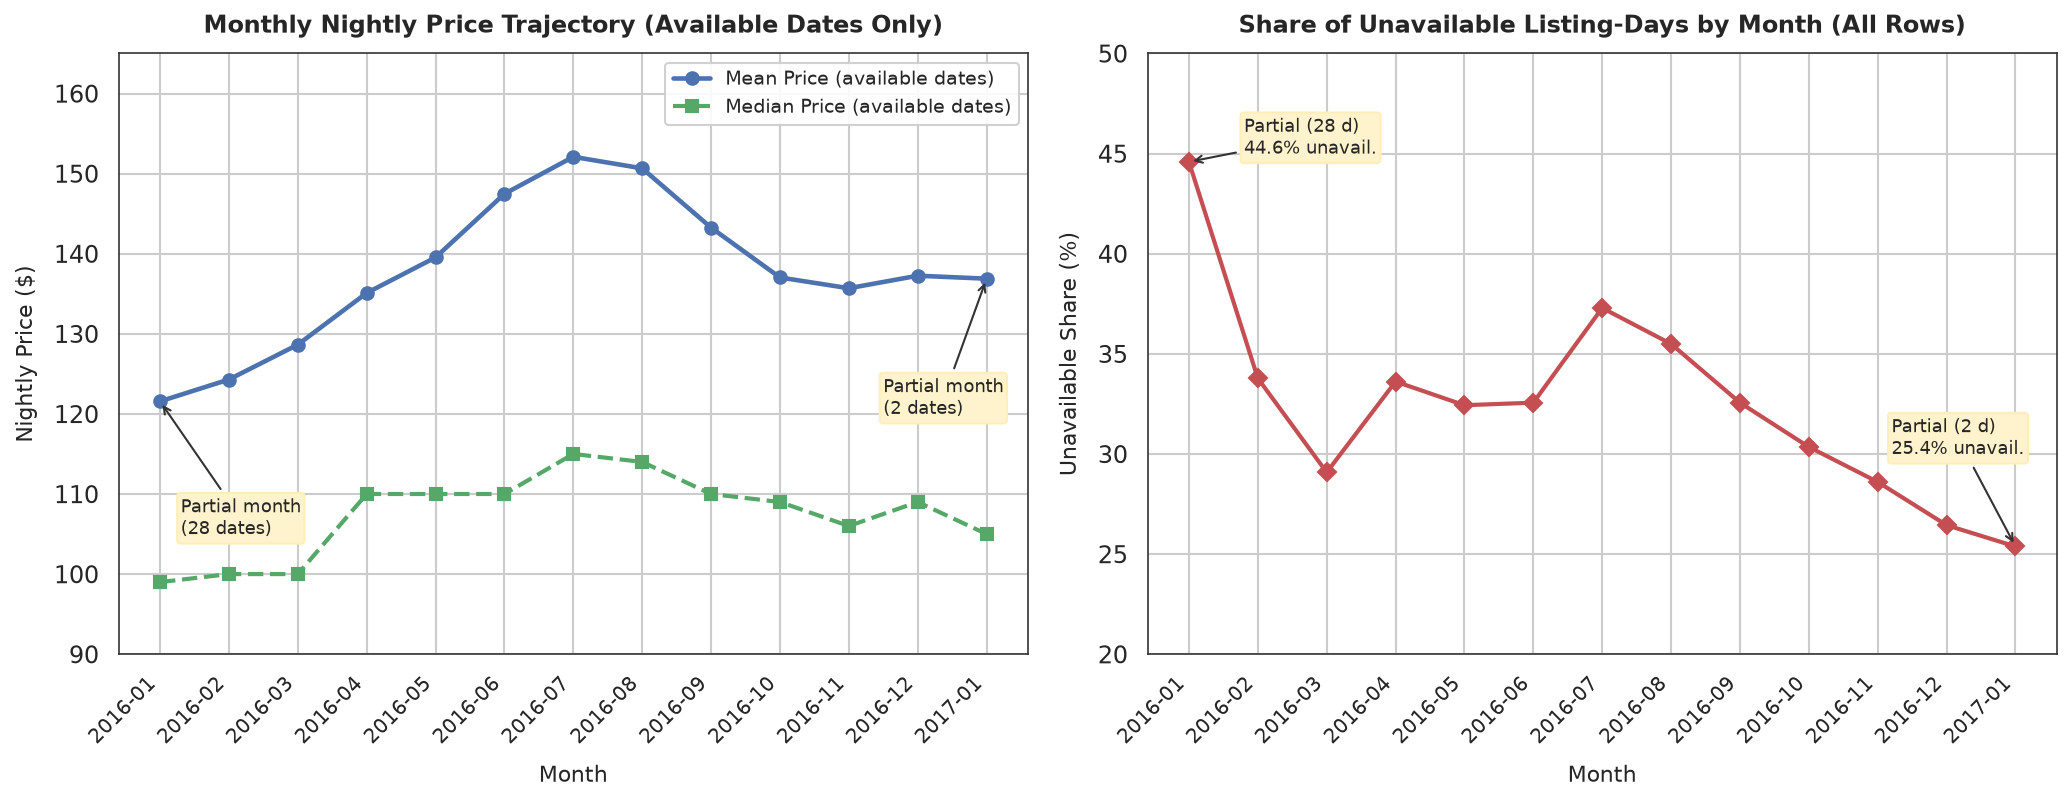

In [14]:
# Plot monthly trajectory: Nightly price (available dates only) and unavailable share (all rows)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

months = list(monthly_stats['year_month'])
x_idx = range(len(months))

# Panel A: Nightly Price Trajectory (available dates only)
ax1.plot(x_idx, monthly_stats['mean_price'], marker='o', linewidth=2.2, color='#4C72B0', label='Mean Price (available dates)')
ax1.plot(x_idx, monthly_stats['median_price'], marker='s', linewidth=2.0, linestyle='--', color='#55A868', label='Median Price (available dates)')
ax1.set_xticks(x_idx)
ax1.set_xticklabels(months, rotation=45, ha='right', fontsize=9.5)
ax1.set_title('Monthly Nightly Price Trajectory (Available Dates Only)', fontsize=11.5, fontweight='bold', pad=10)
ax1.set_xlabel('Month', fontsize=10.5, labelpad=8)
ax1.set_ylabel('Nightly Price ($)', fontsize=10.5, labelpad=8)
ax1.set_ylim(90, 165)
ax1.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=9)

# Annotate incomplete boundary months on Panel A
ax1.annotate('Partial month\n(28 dates)', xy=(0, monthly_stats.loc[0, 'mean_price']), xytext=(0.3, 105),
             arrowprops=dict(arrowstyle='->', color='#333333', lw=1), fontsize=8.5,
             bbox=dict(boxstyle='round,pad=0.2', facecolor='#FFF3CD', edgecolor='#FFEEBA'))
ax1.annotate('Partial month\n(2 dates)', xy=(12, monthly_stats.loc[12, 'mean_price']), xytext=(10.5, 120),
             arrowprops=dict(arrowstyle='->', color='#333333', lw=1), fontsize=8.5,
             bbox=dict(boxstyle='round,pad=0.2', facecolor='#FFF3CD', edgecolor='#FFEEBA'))

# Panel B: Share of Unavailable Listing-Days by Month (all rows)
ax2.plot(x_idx, monthly_stats['unavailable_pct'], marker='D', linewidth=2.0, color='#C44E52')
ax2.set_xticks(x_idx)
ax2.set_xticklabels(months, rotation=45, ha='right', fontsize=9.5)
ax2.set_title('Share of Unavailable Listing-Days by Month (All Rows)', fontsize=11.5, fontweight='bold', pad=10)
ax2.set_xlabel('Month', fontsize=10.5, labelpad=8)
ax2.set_ylabel('Unavailable Share (%)', fontsize=10.5, labelpad=8)
ax2.set_ylim(20, 50)

# Annotate incomplete boundary months on Panel B
ax2.annotate('Partial (28 d)\n44.6% unavail.', xy=(0, monthly_stats.loc[0, 'unavailable_pct']), xytext=(0.8, 45),
             arrowprops=dict(arrowstyle='->', color='#333333', lw=1), fontsize=8.5,
             bbox=dict(boxstyle='round,pad=0.2', facecolor='#FFF3CD', edgecolor='#FFEEBA'))
ax2.annotate('Partial (2 d)\n25.4% unavail.', xy=(12, monthly_stats.loc[12, 'unavailable_pct']), xytext=(10.2, 30),
             arrowprops=dict(arrowstyle='->', color='#333333', lw=1), fontsize=8.5,
             bbox=dict(boxstyle='round,pad=0.2', facecolor='#FFF3CD', edgecolor='#FFEEBA'))

plt.tight_layout()
plt.show()


In [15]:
# 2. Day-of-week breakdown and observed price difference calculation
day_names = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_stats = []

for dow_idx, name in enumerate(day_names):
    sub = df_cal[df_cal['date'].dt.dayofweek == dow_idx]
    avail = sub[sub['available']]
    tot = len(sub)
    n_avail = len(avail)
    n_unavail = tot - n_avail
    unavail_pct = (n_unavail / tot) * 100
    
    dow_stats.append({
        'Day of Week': name,
        'Total Listing-Days (N)': tot,
        'Available Listing-Days (N)': n_avail,
        'Unavailable Listing-Days (N)': n_unavail,
        'Unavailable Share (%)': unavail_pct,
        'Mean Price ($)': avail['price'].mean(),
        'Median Price ($)': avail['price'].median()
    })

df_dow = pd.DataFrame(dow_stats)

# Calculate dynamic difference between Friday–Saturday and Sunday–Thursday
df_cal['is_fri_sat'] = df_cal['date'].dt.dayofweek.isin([4, 5])
avail_cal = df_cal[df_cal['available']]

mean_fri_sat = avail_cal[avail_cal['is_fri_sat']]['price'].mean()
mean_other = avail_cal[~avail_cal['is_fri_sat']]['price'].mean()
diff_dow = mean_fri_sat - mean_other
pct_diff_dow = (diff_dow / mean_other) * 100

# Format display table
display_dow = df_dow.copy()
display_dow['Total Listing-Days (N)'] = display_dow['Total Listing-Days (N)'].map(lambda x: f"{x:,}")
display_dow['Available Listing-Days (N)'] = display_dow['Available Listing-Days (N)'].map(lambda x: f"{x:,}")
display_dow['Unavailable Listing-Days (N)'] = display_dow['Unavailable Listing-Days (N)'].map(lambda x: f"{x:,}")
display_dow['Unavailable Share (%)'] = display_dow['Unavailable Share (%)'].map(lambda x: f"{x:.2f}%")
display_dow['Mean Price ($)'] = display_dow['Mean Price ($)'].map(lambda x: f"${x:.2f}")
display_dow['Median Price ($)'] = display_dow['Median Price ($)'].map(lambda x: f"${x:.2f}")

print("Day-of-Week Summary Table (Prices calculated on available dates only):")
display(display_dow)
print(f"\nObserved Price Difference (Friday–Saturday vs. Sunday–Thursday):")
print(f"  - Friday–Saturday Mean Price: ${mean_fri_sat:.2f}")
print(f"  - Sunday–Thursday Mean Price: ${mean_other:.2f}")
print(f"  - Observed Difference: +${diff_dow:.2f} (+{pct_diff_dow:.2f}%)")


Day-of-Week Summary Table (Prices calculated on available dates only):

Observed Price Difference (Friday–Saturday vs. Sunday–Thursday):
  - Friday–Saturday Mean Price: $143.12
  - Sunday–Thursday Mean Price: $135.89
  - Observed Difference: +$7.23 (+5.32%)


,Day of Week,Total Listing-Days (N),Available Listing-Days (N),Unavailable Listing-Days (N),Unavailable Share (%),Mean Price ($),Median Price ($)
0,Monday,"202,354","135,800","66,554",32.89%,$135.68,$105.00
1,Tuesday,"198,536","133,407","65,129",32.80%,$135.41,$105.00
2,Wednesday,"198,536","133,375","65,161",32.82%,$135.45,$105.00
3,Thursday,"198,536","132,968","65,568",33.03%,$136.48,$105.00
4,Friday,"198,536","132,803","65,733",33.11%,$143.04,$111.00
5,Saturday,"198,536","132,574","65,962",33.22%,$143.20,$113.00
6,Sunday,"198,536","133,615","64,921",32.70%,$136.46,$105.00


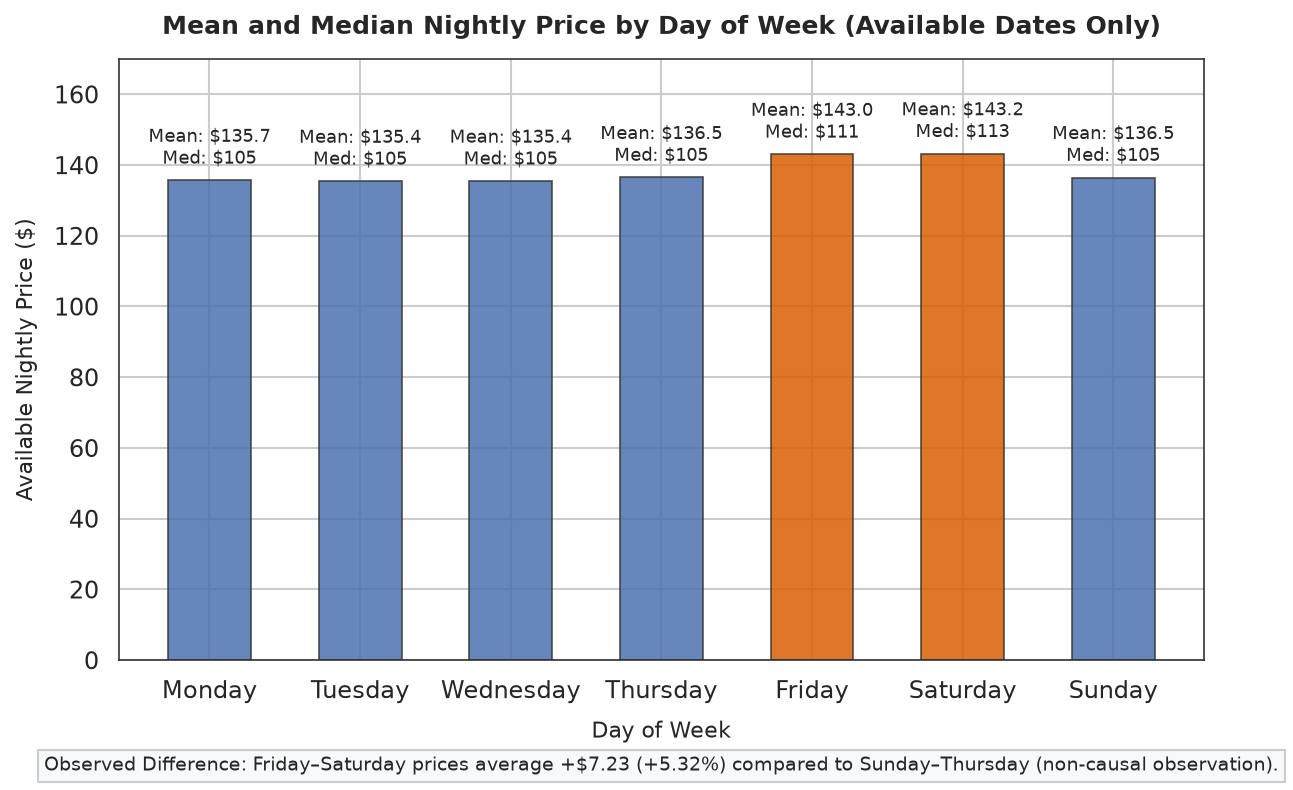

In [16]:
# Plot comparative bar chart of prices across days of the week (available dates only)
fig, ax = plt.subplots(figsize=(9, 5.5))
bar_colors = ['#4C72B0' if d not in ['Friday', 'Saturday'] else '#D95F02' for d in df_dow['Day of Week']]
bars = ax.bar(
    df_dow['Day of Week'],
    df_dow['Mean Price ($)'],
    color=bar_colors,
    width=0.55,
    edgecolor='#333333',
    linewidth=0.8,
    alpha=0.85
)

# Text callouts above bars showing Mean and Median
for bar, med in zip(bars, df_dow['Median Price ($)']):
    yval = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 3.0,
        f"Mean: ${yval:.1f}\nMed: ${med:.0f}",
        ha='center',
        va='bottom',
        fontsize=8.5,
        fontweight='normal'
    )

ax.set_title('Mean and Median Nightly Price by Day of Week (Available Dates Only)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Day of Week', fontsize=10.5, labelpad=8)
ax.set_ylabel('Available Nightly Price ($)', fontsize=10.5, labelpad=8)
ax.set_ylim(0, 170)

# Non-causal callout annotation beneath the plot
ax.annotate(
    f"Observed Difference: Friday–Saturday prices average +${diff_dow:.2f} (+{pct_diff_dow:.2f}%) compared to Sunday–Thursday (non-causal observation).",
    xy=(0.5, -0.16),
    xycoords='axes fraction',
    ha='center',
    va='top',
    fontsize=9,
    bbox=dict(boxstyle='square,pad=0.35', facecolor='#F8F9FA', edgecolor='#CCCCCC')
)

plt.tight_layout()
plt.show()


In [17]:
# 3. Comparison of Metrics across Date Categories
cat_holiday = df_cal['is_holiday']
cat_event_only = df_cal['is_event'] & (~df_cal['is_holiday'])
cat_no_event = (~df_cal['is_event']) & (~df_cal['is_holiday'])

date_categories = [
    ('No event/holiday record in source', cat_no_event),
    ('Federal holiday (including joint record)', cat_holiday),
    ('Event record without federal holiday', cat_event_only)
]

cat_rows = []
for label, mask in date_categories:
    sub = df_cal[mask]
    avail_sub = sub[sub['available']]
    tot = len(sub)
    n_avail = len(avail_sub)
    n_unavail = tot - n_avail
    unavail_pct = (n_unavail / tot) * 100
    
    cat_rows.append({
        'Date Category': label,
        'Dates (N)': sub['date'].nunique(),
        'Listing-Days (N)': tot,
        'Available Rows (N)': n_avail,
        'Unavailable Rows (N)': n_unavail,
        'Unavailable Share (%)': unavail_pct,
        'Mean Price ($)': avail_sub['price'].mean(),
        'Median Price ($)': avail_sub['price'].median()
    })

df_cats = pd.DataFrame(cat_rows)

# Calculate observed differences relative to regular dates from unrounded means
mean_no_event = df_cats.loc[df_cats['Date Category'] == 'No event/holiday record in source', 'Mean Price ($)'].iloc[0]
mean_holiday = df_cats.loc[df_cats['Date Category'] == 'Federal holiday (including joint record)', 'Mean Price ($)'].iloc[0]
mean_event_only = df_cats.loc[df_cats['Date Category'] == 'Event record without federal holiday', 'Mean Price ($)'].iloc[0]

diff_holiday = mean_holiday - mean_no_event
pct_diff_holiday = (diff_holiday / mean_no_event) * 100

diff_event = mean_event_only - mean_no_event
pct_diff_event = (diff_event / mean_no_event) * 100

# Format display table
display_cats = df_cats.copy()
display_cats['Dates (N)'] = display_cats['Dates (N)'].map(lambda x: f"{x}")
display_cats['Listing-Days (N)'] = display_cats['Listing-Days (N)'].map(lambda x: f"{x:,}")
display_cats['Available Rows (N)'] = display_cats['Available Rows (N)'].map(lambda x: f"{x:,}")
display_cats['Unavailable Rows (N)'] = display_cats['Unavailable Rows (N)'].map(lambda x: f"{x:,}")
display_cats['Unavailable Share (%)'] = display_cats['Unavailable Share (%)'].map(lambda x: f"{x:.2f}%")
display_cats['Mean Price ($)'] = display_cats['Mean Price ($)'].map(lambda x: f"${x:.2f}")
display_cats['Median Price ($)'] = display_cats['Median Price ($)'].map(lambda x: f"${x:.2f}")

print("Comparison of Metrics across Date Categories (Prices calculated on available dates only):")
display(display_cats)
print(f"\nObserved Price Differences vs. No event/holiday record (${mean_no_event:.2f}):")
print(f"  - Federal holiday (including joint record): -${abs(diff_holiday):.2f} ({pct_diff_holiday:.2f}%)")
print(f"  - Event record without federal holiday: +${diff_event:.2f} (+{pct_diff_event:.2f}%)")


Comparison of Metrics across Date Categories (Prices calculated on available dates only):

Observed Price Differences vs. No event/holiday record ($137.67):
  - Federal holiday (including joint record): -$0.72 (-0.53%)
  - Event record without federal holiday: +$13.56 (+9.85%)


,Date Category,Dates (N),Listing-Days (N),Available Rows (N),Unavailable Rows (N),Unavailable Share (%),Mean Price ($),Median Price ($)
0,No event/holiday record in source,347,"1,324,846","888,510","436,336",32.93%,$137.67,$109.00
1,Federal holiday (including joint record),10,"38,180","25,979","12,201",31.96%,$136.95,$105.00
2,Event record without federal holiday,8,"30,544","20,053","10,491",34.35%,$151.24,$115.00


### 5.4 Factual Findings on Calendar Dynamics & Prospective Variations

1. **Prospective Nature of the Calendar Snapshot & Boundary Months:**
   - The calendar dataset contains **1,393,570 listing-days** recorded across 365 dates from **January 4, 2016** to **January 2, 2017**.
   - These records reflect host-advertised nightly prices and calendar availability as of the snapshot scrape date (January 4, 2016). They do not represent realized transactions, historical guest volume, or confirmed bookings.
   - **Boundary Incomplete Months:** **January 2016** contains only **28 dates** (106,904 listing-days) and **January 2017** contains only **2 dates** (7,636 listing-days). The observed unavailable share is **44.59%** in January 2016 and **25.38%** in January 2017; the specific causes of these availability rates are not established by the dataset. Neither boundary month represents a full 30- or 31-day cycle and cannot be directly compared to complete months.

2. **Monthly Variation in Advertised Prices & Calendar Availability:**
   - Across full calendar months (February–December 2016), advertised mean prices on available dates follow a distinct summer peak:
     - Lowest full-month mean prices occur in late winter and early spring: **February ($124.29)**, **March ($128.64)**, and **April ($135.10)**.
     - Highest mean prices occur in mid-summer: **June ($147.47)**, **July ($152.09)**, and **August ($150.66)**.
     - Autumn and early winter stabilize at intermediate levels: **September ($143.26)**, **October ($137.03)**, **November ($135.69)**, and **December ($137.25)**.
   - Median advertised prices similarly peak at **$115.00** in July and **$114.00** in August, compared to **$100.00** in February and March.
   - Share of unavailable listing-days among complete months ranges from **26.44%** (December) and **28.60%** (November) up to **37.29%** (July) and **35.49%** (August). These variations capture prospective availability configurations rather than verified seasonal demand.

3. **Observed Day-of-Week Price Variation:**
   - Listings marked available exhibit an observed price difference between weekend and weekday dates:
     - **Friday–Saturday available mean price:** **$143.12** ($Median = \$111.00$ on Friday, $\$113.00$ on Saturday).
     - **Sunday–Thursday available mean price:** **$135.89** ($Median = \$105.00$ on Sunday–Thursday).
     - **Observed Difference:** Advertised prices for Friday and Saturday are **+$7.23 (+5.32%)** higher on average than for Sunday through Thursday.
   - Unavailable shares remain virtually uniform across all seven days of the week, ranging narrowly between **32.70%** (Sunday) and **33.22%** (Saturday).
   - This observed difference describes host pricing behavior in the prospective calendar and does not establish a causal "weekend effect" on guest occupancy.

4. **Comparison of Metrics across Date Categories:**
   - Partitioning the calendar into three mutually exclusive groups reveals distinct empirical profiles:
     - **`No event/holiday record in source` (347 dates, 1,324,846 listing-days):** Available mean price is **$137.67** ($Median = \$109.00$), with an unavailable share of **32.93%**.
     - **`Federal holiday (including joint record)` (10 dates, 38,180 listing-days):** Available mean price is **$136.95** ($Median = \$105.00$), with an unavailable share of **31.96%**. Advertised holiday prices do not show an aggregate premium over regular non-event dates (**-$0.72** or **-0.53%** difference).
     - **`Event record without federal holiday` (8 dates, 30,544 listing-days):** Available mean price is **$151.24** ($Median = \$115.00$), with an unavailable share of **34.35%**. While this category displays an observed price difference of **+$13.56 (+9.85%)** over regular dates (calculated from unrounded group means), it is based on only 8 distinct calendar dates in 2016.
   - Due to the small number of recorded event dates and the absence of individual transaction records, these variations represent empirical contrasts in the prospective calendar snapshot rather than evidence of causal event premiums.


## 6. Reviews, Guest Ratings & Host Characteristics

In this section, we examine the customer review metrics and host attributes recorded in `listings_clean.csv` ($N = 3,818$ listings across $2,751$ unique `host_id` values), addressing the review and host performance questions from the approved project proposal:

1. **Review Coverage & Missingness Structure:** We quantify valid and missing observations across review count and rating variables, explicitly distinguishing listings with zero reviews (`number_of_reviews == 0`) from reviewed listings (`number_of_reviews > 0`) that lack numerical rating scores.
2. **Distribution of Review Counts & Guest Ratings:** We compute descriptive statistics and plot 30-bin histograms for `number_of_reviews` and overall `review_scores_rating`, alongside a horizontal bar chart comparing the six individual review sub-scores (`communication`, `checkin`, `accuracy`, `location`, `cleanliness`, `value`). Because the CSV source alone confirms empirical values rather than theoretical lower scale bounds, we report the **Observed Range** (`Minimum–Maximum`) for each metric.
3. **Host Characteristics (`host_is_superhost`, `host_response_time`, `host_response_rate`):** Treating the **individual listing** as the unit of analysis, we compare review volume, rating scores, and base prices across host categories. All missing values are preserved in an explicit `Missing` category, and group tables report both total listing counts (`Listing Count (N)`) and the exact number of non-null rating observations (`Valid Rating Count (N)`) used to compute group means and medians.


In [18]:
# 1. Review Coverage & Missingness Structure Breakdown
n_total_listings = len(df_listings)
n_unique_hosts = df_listings['host_id'].nunique()

mask_zero_rev = df_listings['number_of_reviews'] == 0
mask_pos_rev = df_listings['number_of_reviews'] > 0
mask_pos_with_rating = mask_pos_rev & df_listings['review_scores_rating'].notna()
mask_pos_no_rating = mask_pos_rev & df_listings['review_scores_rating'].isna()

# Verify exact concordance between listings number_of_reviews and aggregated reviews.csv counts
rev_concordance = (
    df_listings.loc[mask_pos_rev, 'number_of_reviews'].astype('Int64')
    == df_listings.loc[mask_pos_rev, 'rev_count_from_reviews']
).all()

coverage_breakdown = pd.DataFrame([
    {
        'Listing Review Group': 'Reviewed listings with overall rating (number_of_reviews > 0, rating present)',
        'Listing Count (N)': int(mask_pos_with_rating.sum()),
        'Share of Total Sample (%)': f"{mask_pos_with_rating.mean() * 100:.2f}%",
        'Overall Rating Status': 'Present (3,171 valid ratings)'
    },
    {
        'Listing Review Group': 'Reviewed listings missing overall rating (number_of_reviews > 0, rating missing)',
        'Listing Count (N)': int(mask_pos_no_rating.sum()),
        'Share of Total Sample (%)': f"{mask_pos_no_rating.mean() * 100:.2f}%",
        'Overall Rating Status': 'Missing (20 reviewed listings without rating)'
    },
    {
        'Listing Review Group': 'Unreviewed listings (number_of_reviews == 0)',
        'Listing Count (N)': int(mask_zero_rev.sum()),
        'Share of Total Sample (%)': f"{mask_zero_rev.mean() * 100:.2f}%",
        'Overall Rating Status': 'Missing (627 listings with 0 reviews)'
    },
    {
        'Listing Review Group': 'Total Sample (All Listings)',
        'Listing Count (N)': n_total_listings,
        'Share of Total Sample (%)': '100.00%',
        'Overall Rating Status': f"{int(df_listings['review_scores_rating'].notna().sum()):,} valid / {int(df_listings['review_scores_rating'].isna().sum()):,} missing (16.95%)"
    }
])
coverage_breakdown['Listing Count (N)'] = coverage_breakdown['Listing Count (N)'].map(lambda x: f"{x:,}")

print(f"Unit of analysis: {n_total_listings:,} listings across {n_unique_hosts:,} unique host_id values.")
print(f"Concordance check (number_of_reviews == rev_count_from_reviews for all 3,191 reviewed listings): {rev_concordance}")
print("\nReview Coverage and Overall Rating Missingness Breakdown:")
display(coverage_breakdown)

# 2. Descriptive Statistics for Review Counts and Guest Ratings across Full Sample (N = 3,818)
review_metric_specs = [
    ('number_of_reviews', df_listings['number_of_reviews'].astype(float)),
    ('reviews_per_month', df_listings['reviews_per_month'].astype(float)),
    ('review_scores_rating (Overall)', df_listings['review_scores_rating'].astype(float)),
    ('review_scores_communication', df_listings['review_scores_communication'].astype(float)),
    ('review_scores_checkin', df_listings['review_scores_checkin'].astype(float)),
    ('review_scores_accuracy', df_listings['review_scores_accuracy'].astype(float)),
    ('review_scores_location', df_listings['review_scores_location'].astype(float)),
    ('review_scores_cleanliness', df_listings['review_scores_cleanliness'].astype(float)),
    ('review_scores_value', df_listings['review_scores_value'].astype(float))
]

rev_stats_rows = []
for label, series in review_metric_specs:
    valid = series.dropna()
    n_val = len(valid)
    n_miss = n_total_listings - n_val
    q1 = valid.quantile(0.25)
    q3 = valid.quantile(0.75)
    iqr_val = q3 - q1
    
    rev_stats_rows.append({
        'Metric': label,
        'Valid Count (N)': f"{n_val:,}",
        'Missing Count (N)': f"{n_miss:,}",
        'Missing Share (%)': f"{(n_miss / n_total_listings) * 100:.2f}%",
        'Observed Range': f"{valid.min():.2f}–{valid.max():.2f}",
        'Mean': f"{valid.mean():.2f}",
        'Standard Deviation': f"{valid.std():.2f}",
        'Minimum': f"{valid.min():.2f}",
        'Q1': f"{q1:.2f}",
        'Median': f"{valid.median():.2f}",
        'Q3': f"{q3:.2f}",
        'Maximum': f"{valid.max():.2f}",
        'IQR': f"{iqr_val:.2f}"
    })

df_rev_stats = pd.DataFrame(rev_stats_rows)
print("\nDescriptive Statistics for Review Counts and Guest Ratings across Full Sample (N = 3,818 Listings):")
display(df_rev_stats)

# Separate summary for the subset of 3,191 reviewed listings (number_of_reviews > 0, 0 missing within subset)
rev_pos = df_listings.loc[mask_pos_rev, 'number_of_reviews'].astype(float)
rev_pos_q1 = rev_pos.quantile(0.25)
rev_pos_q3 = rev_pos.quantile(0.75)
df_rev_pos_subset = pd.DataFrame([{
    'Subset': 'Reviewed Listings Only (number_of_reviews > 0)',
    'Subset Size (N)': f"{len(rev_pos):,}",
    'Missing in Subset (N)': int(rev_pos.isna().sum()),
    'Observed Range': f"{rev_pos.min():.2f}–{rev_pos.max():.2f}",
    'Mean': f"{rev_pos.mean():.2f}",
    'Standard Deviation': f"{rev_pos.std():.2f}",
    'Minimum': f"{rev_pos.min():.2f}",
    'Q1': f"{rev_pos_q1:.2f}",
    'Median': f"{rev_pos.median():.2f}",
    'Q3': f"{rev_pos_q3:.2f}",
    'Maximum': f"{rev_pos.max():.2f}",
    'IQR': f"{(rev_pos_q3 - rev_pos_q1):.2f}"
}])
print("\nSeparate Descriptive Statistics for number_of_reviews within the Reviewed Subset (number_of_reviews > 0):")
display(df_rev_pos_subset)


Unit of analysis: 3,818 listings across 2,751 unique host_id values.
Concordance check (number_of_reviews == rev_count_from_reviews for all 3,191 reviewed listings): True

Review Coverage and Overall Rating Missingness Breakdown:

Descriptive Statistics for Review Counts and Guest Ratings across Full Sample (N = 3,818 Listings):

Separate Descriptive Statistics for number_of_reviews within the Reviewed Subset (number_of_reviews > 0):


,Listing Review Group,Listing Count (N),Share of Total Sample (%),Overall Rating Status
0,"Reviewed listings with overall rating (number_of_reviews > 0, rating present)","3,171",83.05%,"Present (3,171 valid ratings)"
1,"Reviewed listings missing overall rating (number_of_reviews > 0, rating missing)",20,0.52%,Missing (20 reviewed listings without rating)
2,Unreviewed listings (number_of_reviews == 0),627,16.42%,Missing (627 listings with 0 reviews)
3,Total Sample (All Listings),"3,818",100.00%,"3,171 valid / 647 missing (16.95%)"


,Metric,Valid Count (N),Missing Count (N),Missing Share (%),Observed Range,Mean,Standard Deviation,Minimum,Q1,Median,Q3,Maximum,IQR
0,number_of_reviews,"3,818",0,0.00%,0.00–474.00,22.22,37.73,0.00,2.00,9.00,26.00,474.00,24.00
1,reviews_per_month,"3,191",627,16.42%,0.02–12.15,2.08,1.82,0.02,0.69,1.54,3.00,12.15,2.31
2,review_scores_rating (Overall),"3,171",647,16.95%,20.00–100.00,94.54,6.61,20.00,93.00,96.00,99.00,100.00,6.00
3,review_scores_communication,"3,167",651,17.05%,2.00–10.00,9.81,0.57,2.00,10.00,10.00,10.00,10.00,0.00
4,review_scores_checkin,"3,160",658,17.23%,2.00–10.00,9.79,0.60,2.00,10.00,10.00,10.00,10.00,0.00
5,review_scores_accuracy,"3,160",658,17.23%,2.00–10.00,9.64,0.70,2.00,9.00,10.00,10.00,10.00,1.00
6,review_scores_location,"3,163",655,17.16%,4.00–10.00,9.61,0.63,4.00,9.00,10.00,10.00,10.00,1.00
7,review_scores_cleanliness,"3,165",653,17.10%,3.00–10.00,9.56,0.80,3.00,9.00,10.00,10.00,10.00,1.00
8,review_scores_value,"3,162",656,17.18%,2.00–10.00,9.45,0.75,2.00,9.00,10.00,10.00,10.00,1.00


,Subset,Subset Size (N),Missing in Subset (N),Observed Range,Mean,Standard Deviation,Minimum,Q1,Median,Q3,Maximum,IQR
0,Reviewed Listings Only (number_of_reviews > 0),"3,191",0,1.00–474.00,26.59,39.84,1.00,4.00,13.00,31.00,474.00,27.00


Listings above Upper IQR Bound (62.00 reviews): 364 listings (9.53% of sample).


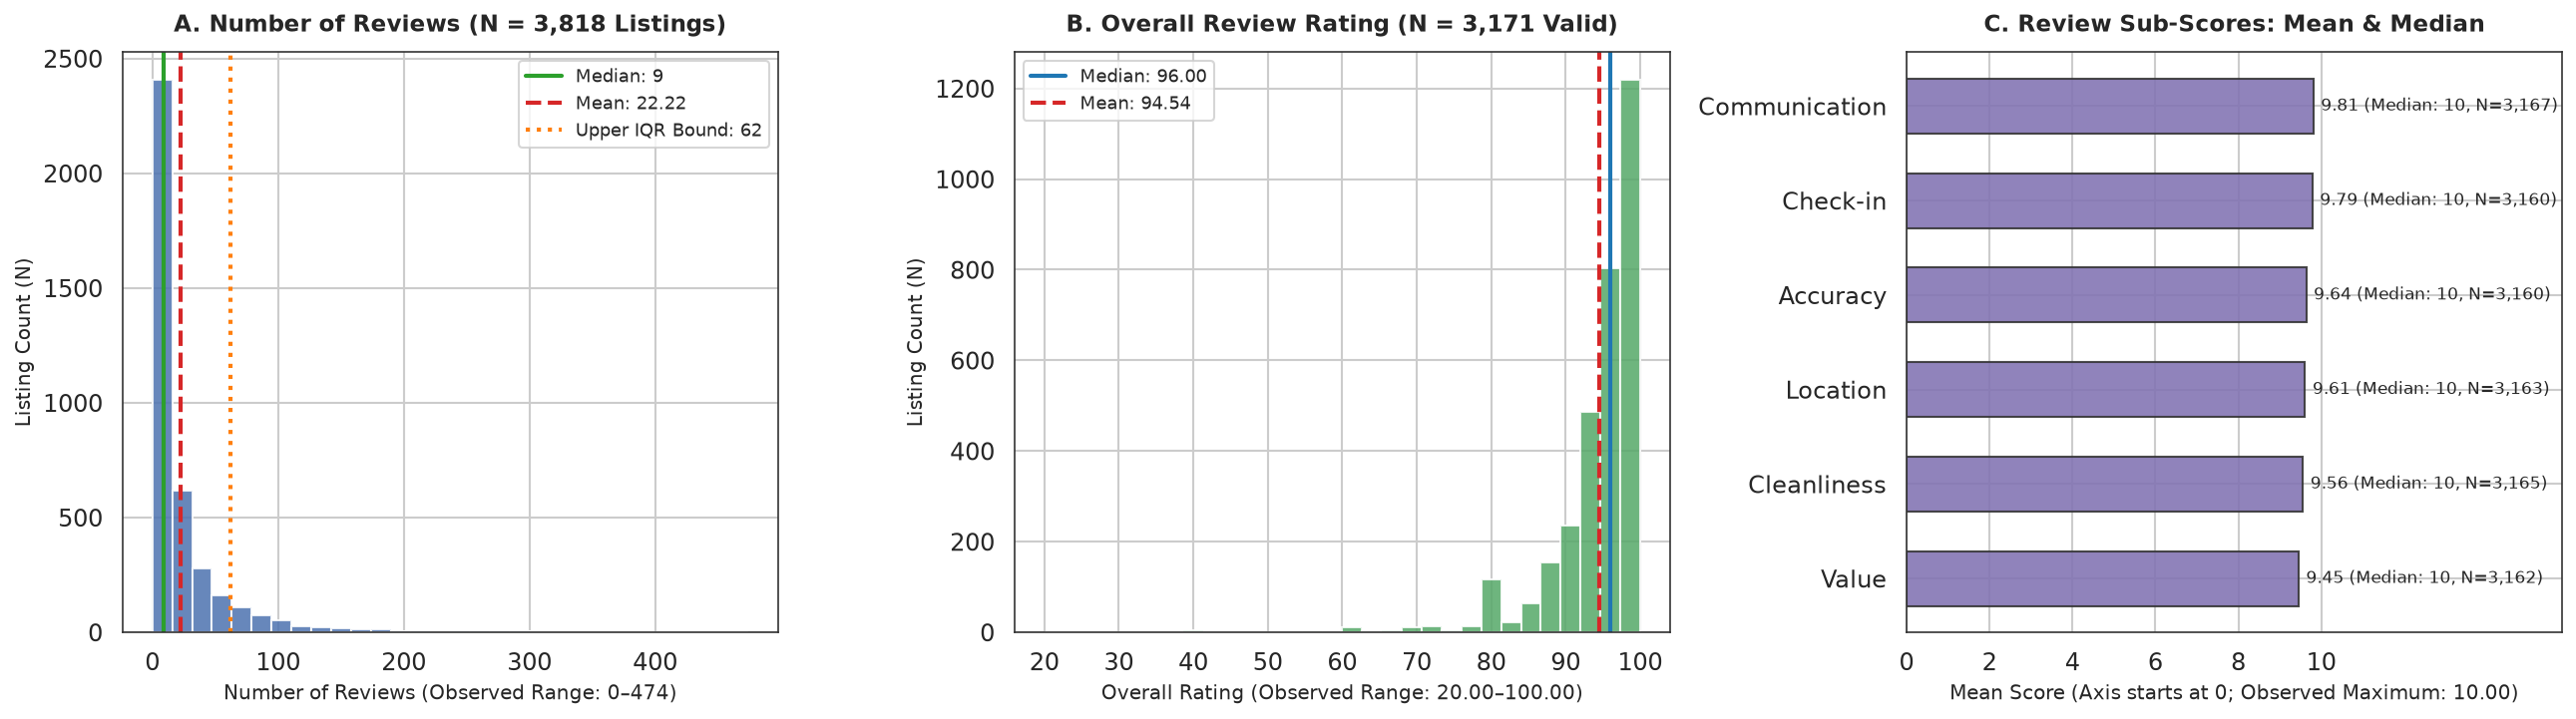

In [19]:
# 3. Visualizations of Review Counts, Overall Rating, and Sub-Scores (30 bins for histograms)
fig, axes = plt.subplots(1, 3, figsize=(17.5, 5.0))

# Panel A: Distribution of number_of_reviews (All listings, 30 bins)
rev_all = df_listings['number_of_reviews'].dropna().astype(float)
n_rev_all = len(rev_all)
rev_min = rev_all.min()
rev_max = rev_all.max()
rev_mean = rev_all.mean()
rev_median = rev_all.median()
rev_q1 = rev_all.quantile(0.25)
rev_q3 = rev_all.quantile(0.75)
rev_iqr_upper = rev_q3 + 1.5 * (rev_q3 - rev_q1)
n_rev_outliers = int((rev_all > rev_iqr_upper).sum())
pct_rev_outliers = (n_rev_outliers / n_rev_all) * 100

axes[0].hist(rev_all, bins=30, color='#4C72B0', edgecolor='white', alpha=0.85)
axes[0].axvline(rev_median, color='#2CA02C', linestyle='-', linewidth=2, label=f'Median: {rev_median:.0f}')
axes[0].axvline(rev_mean, color='#D62728', linestyle='--', linewidth=2, label=f'Mean: {rev_mean:.2f}')
axes[0].axvline(rev_iqr_upper, color='#FF7F0E', linestyle=':', linewidth=2, label=f'Upper IQR Bound: {rev_iqr_upper:.0f}')
axes[0].set_title(f'A. Number of Reviews (N = {n_rev_all:,} Listings)', fontsize=11, fontweight='bold', pad=10)
axes[0].set_xlabel(f'Number of Reviews (Observed Range: {rev_min:.0f}–{rev_max:.0f})', fontsize=9.5)
axes[0].set_ylabel('Listing Count (N)', fontsize=9.5)
axes[0].legend(loc='upper right', fontsize=8.5, frameon=True)

# Panel B: Distribution of review_scores_rating (Valid listings, 30 bins)
rat_valid = df_listings['review_scores_rating'].dropna().astype(float)
n_rat_valid = len(rat_valid)
rat_min = rat_valid.min()
rat_max = rat_valid.max()
rat_mean = rat_valid.mean()
rat_median = rat_valid.median()

axes[1].hist(rat_valid, bins=30, color='#55A868', edgecolor='white', alpha=0.85)
axes[1].axvline(rat_median, color='#1F77B4', linestyle='-', linewidth=2, label=f'Median: {rat_median:.2f}')
axes[1].axvline(rat_mean, color='#D62728', linestyle='--', linewidth=2, label=f'Mean: {rat_mean:.2f}')
axes[1].set_title(f'B. Overall Review Rating (N = {n_rat_valid:,} Valid)', fontsize=11, fontweight='bold', pad=10)
axes[1].set_xlabel(f'Overall Rating (Observed Range: {rat_min:.2f}–{rat_max:.2f})', fontsize=9.5)
axes[1].set_ylabel('Listing Count (N)', fontsize=9.5)
axes[1].legend(loc='upper left', fontsize=8.5, frameon=True)

# Panel C: Horizontal Bar Chart of Six Review Sub-Scores (x-axis starting at 0)
subscore_cols = [
    ('Communication', 'review_scores_communication'),
    ('Check-in', 'review_scores_checkin'),
    ('Accuracy', 'review_scores_accuracy'),
    ('Location', 'review_scores_location'),
    ('Cleanliness', 'review_scores_cleanliness'),
    ('Value', 'review_scores_value')
]
# Reverse order so highest mean appears at the top of horizontal bar chart
subscore_cols_rev = list(reversed(subscore_cols))
sub_labels = [lbl for lbl, _ in subscore_cols_rev]
sub_means = [df_listings[col].dropna().mean() for _, col in subscore_cols_rev]
sub_medians = [df_listings[col].dropna().median() for _, col in subscore_cols_rev]
sub_counts = [int(df_listings[col].notna().sum()) for _, col in subscore_cols_rev]
sub_obs_max = max(df_listings[col].dropna().max() for _, col in subscore_cols_rev)

bars = axes[2].barh(sub_labels, sub_means, color='#8172B2', edgecolor='#333333', height=0.58, alpha=0.88)
axes[2].set_xlim(0, 15.8)
axes[2].set_xticks([0, 2, 4, 6, 8, 10])
axes[2].set_title('C. Review Sub-Scores: Mean & Median', fontsize=11, fontweight='bold', pad=10)
axes[2].set_xlabel(f'Mean Score (Axis starts at 0; Observed Maximum: {sub_obs_max:.2f})', fontsize=9.5)

for bar, m_val, med_val, cnt_val in zip(bars, sub_means, sub_medians, sub_counts):
    axes[2].text(
        m_val + 0.18,
        bar.get_y() + bar.get_height() / 2.0,
        f"{m_val:.2f} (Median: {med_val:.0f}, N={cnt_val:,})",
        va='center',
        ha='left',
        fontsize=8.2
    )

plt.tight_layout()
plt.show()

print(f"Listings above Upper IQR Bound ({rev_iqr_upper:.2f} reviews): {n_rev_outliers} listings ({pct_rev_outliers:.2f}% of sample).")


In [20]:
# 4. Host Characteristics Comparison at the Listing Level (N = 3,818 listings across 2,751 unique hosts)
# 4a. Group comparison by host_is_superhost (including explicit Missing category)
superhost_groups = [
    ('Superhost (True)', df_listings['host_is_superhost'].fillna(False) & df_listings['host_is_superhost'].notna()),
    ('Non-Superhost (False)', (~df_listings['host_is_superhost'].fillna(True)) & df_listings['host_is_superhost'].notna()),
    ('Missing', df_listings['host_is_superhost'].isna())
]

sh_rows = []
for label, mask in superhost_groups:
    sub = df_listings[mask]
    n_grp = len(sub)
    n_rev_grp = int((sub['number_of_reviews'] > 0).sum())
    valid_rat = sub['review_scores_rating'].dropna().astype(float)
    n_rat = len(valid_rat)
    
    sh_rows.append({
        'Host Superhost Status': label,
        'Listing Count (N)': f"{n_grp:,}",
        'Share of Sample (%)': f"{(n_grp / n_total_listings) * 100:.2f}%",
        'Unique Hosts (N)': f"{sub['host_id'].nunique():,}",
        'Reviewed Listings (N)': f"{n_rev_grp:,}",
        'Mean Reviews': f"{sub['number_of_reviews'].mean():.2f}",
        'Median Reviews': f"{sub['number_of_reviews'].median():.2f}",
        'Valid Rating Count (N)': f"{n_rat:,}",
        'Mean Rating': f"{valid_rat.mean():.2f}" if n_rat > 0 else 'N/A',
        'Median Rating': f"{valid_rat.median():.2f}" if n_rat > 0 else 'N/A',
        'Mean Price ($)': f"${sub['price'].mean():.2f}",
        'Median Price ($)': f"${sub['price'].median():.2f}"
    })

df_superhost_summary = pd.DataFrame(sh_rows)
print("Listing-Level Comparison by Host Superhost Status (Denominators shown separately for Listings vs. Valid Ratings):")
display(df_superhost_summary)

# 4b. Group comparison by host_response_time (including explicit Missing category)
response_time_order = [
    'within an hour',
    'within a few hours',
    'within a day',
    'a few days or more',
    'Missing'
]

rt_rows = []
for rt_label in response_time_order:
    if rt_label == 'Missing':
        sub = df_listings[df_listings['host_response_time'].isna()]
    else:
        sub = df_listings[df_listings['host_response_time'] == rt_label]
        
    n_grp = len(sub)
    n_rev_grp = int((sub['number_of_reviews'] > 0).sum())
    valid_rr = sub['host_response_rate'].dropna().astype(float)
    n_rr = len(valid_rr)
    valid_rat = sub['review_scores_rating'].dropna().astype(float)
    n_rat = len(valid_rat)
    
    rt_rows.append({
        'Host Response Time': rt_label,
        'Listing Count (N)': f"{n_grp:,}",
        'Share of Sample (%)': f"{(n_grp / n_total_listings) * 100:.2f}%",
        'Valid Response Rate Count (N)': f"{n_rr:,}",
        'Mean Response Rate (%)': f"{valid_rr.mean():.2f}%" if n_rr > 0 else 'N/A',
        'Median Response Rate (%)': f"{valid_rr.median():.2f}%" if n_rr > 0 else 'N/A',
        'Reviewed Listings (N)': f"{n_rev_grp:,}",
        'Mean Reviews': f"{sub['number_of_reviews'].mean():.2f}",
        'Median Reviews': f"{sub['number_of_reviews'].median():.2f}",
        'Valid Rating Count (N)': f"{n_rat:,}",
        'Mean Rating': f"{valid_rat.mean():.2f}" if n_rat > 0 else 'N/A',
        'Median Rating': f"{valid_rat.median():.2f}" if n_rat > 0 else 'N/A',
        'Mean Price ($)': f"${sub['price'].mean():.2f}",
        'Median Price ($)': f"${sub['price'].median():.2f}"
    })

df_response_summary = pd.DataFrame(rt_rows)
print("\nListing-Level Comparison by Host Response Time (Including Explicit Missing Category and Separate Denominators):")
display(df_response_summary)


Listing-Level Comparison by Host Superhost Status (Denominators shown separately for Listings vs. Valid Ratings):

Listing-Level Comparison by Host Response Time (Including Explicit Missing Category and Separate Denominators):


,Host Superhost Status,Listing Count (N),Share of Sample (%),Unique Hosts (N),Reviewed Listings (N),Mean Reviews,Median Reviews,Valid Rating Count (N),Mean Rating,Median Rating,Mean Price ($),Median Price ($)
0,Superhost (True),778,20.38%,537,751,41.76,28.00,751,97.40,98.00,$130.14,$103.00
1,Non-Superhost (False),"3,038",79.57%,"2,212","2,440",17.24,6.00,"2,420",93.65,95.00,$127.39,$100.00
2,Missing,2,0.05%,2,0,0.00,0.00,0,N/A,N/A,$174.50,$174.50


,Host Response Time,Listing Count (N),Share of Sample (%),Valid Response Rate Count (N),Mean Response Rate (%),Median Response Rate (%),Reviewed Listings (N),Mean Reviews,Median Reviews,Valid Rating Count (N),Mean Rating,Median Rating,Mean Price ($),Median Price ($)
0,within an hour,"1,692",44.32%,"1,692",98.71%,100.00%,"1,526",28.88,14.00,"1,521",95.14,96.00,$116.36,$99.00
1,within a few hours,968,25.35%,968,95.90%,100.00%,840,24.85,11.00,837,93.81,96.00,$133.82,$100.00
2,within a day,597,15.64%,597,86.25%,93.00%,476,13.14,5.00,472,94.26,96.00,$132.82,$109.00
3,a few days or more,38,1.00%,38,34.79%,33.00%,29,11.66,4.00,29,87.79,94.00,$129.16,$107.50
4,Missing,523,13.70%,0,N/A,N/A,320,6.96,1.00,312,94.58,97.00,$149.12,$120.00


### 6.1 Factual Findings on Reviews, Guest Ratings & Host Characteristics

1. **Review Coverage and Missingness Structure ($N = 3,818$ Listings):**
   - `number_of_reviews` is complete across all **3,818 listings (0.00% missing)**.
   - Exactly **627 listings (16.42%)** have zero reviews (`number_of_reviews == 0`), while **3,191 listings (83.58%)** have at least one review (`number_of_reviews > 0`). Within the subset of 3,191 reviewed listings, there are **0 missing values** for `number_of_reviews`, and the counts match `rev_count_from_reviews` aggregated from `reviews.csv`.
   - Overall rating (`review_scores_rating`) is present for **3,171 listings (83.05%)** and missing for **647 listings (16.95%)**. These 647 missing records consist of all **627 unreviewed listings** plus **20 listings** that have at least one review (`number_of_reviews > 0`) but no recorded overall rating.
   - Missing counts across the six individual review sub-scores range from **651 listings (17.05%)** for `review_scores_communication` to **658 listings (17.23%)** for `review_scores_accuracy` and `review_scores_checkin`.

2. **Distribution of Review Counts (`number_of_reviews` and `reviews_per_month`):**
   - Across all 3,818 listings, `number_of_reviews` spans an **Observed Range of 0.00–474.00** and is strongly right-skewed: **Mean = 22.22**, **Standard Deviation = 37.73**, **$Q_1 = 2.00$**, **Median = 9.00**, **$Q_3 = 26.00$**, and **$IQR = 24.00$** (**Upper IQR Bound = 62.00**, with **364 listings / 9.53%** above this bound).
   - Within the separate subset of **3,191 reviewed listings** (`number_of_reviews > 0`, 0 missing values in subset), the **Observed Range is 1.00–474.00**, with **Mean = 26.59**, **Standard Deviation = 39.84**, **$Q_1 = 4.00$**, **Median = 13.00**, **$Q_3 = 31.00$**, and **$IQR = 27.00$**.
   - For `reviews_per_month` ($N = 3,191$ valid observations, **627 missing / 16.42%**), the **Observed Range is 0.02–12.15**, with **Mean = 2.08**, **Standard Deviation = 1.82**, **Median = 1.54**, and **$IQR = 2.31$** ($Q_1 = 0.69$, $Q_3 = 3.00$).

3. **Distribution of Overall Rating and Sub-Scores (Observed Ranges):**
   - Because the CSV data alone confirms empirical values rather than theoretical lower scale bounds, ranges are reported strictly as **Observed Ranges**.
   - Across the **3,171 listings** with valid overall ratings (`review_scores_rating`), the **Observed Range is 20.00–100.00**, with a strongly left-skewed distribution concentrated near the upper end: **Mean = 94.54**, **Standard Deviation = 6.61**, **$Q_1 = 93.00$**, **Median = 96.00**, **$Q_3 = 99.00$**, and **$IQR = 6.00$**.
   - Across the six individual sub-scores, the **Observed Range** is **2.00–10.00** for `communication`, `checkin`, `accuracy`, and `value`, **3.00–10.00** for `cleanliness`, and **4.00–10.00** for `location`. Every sub-score has a **Median of 10.00**, while means range from **9.45** (`review_scores_value`, Standard Deviation = 0.75) to **9.81** (`review_scores_communication`, Standard Deviation = 0.57).

4. **Host Characteristics at the Listing Level ($N = 3,818$ Listings across $2,751$ Unique Hosts):**
   - **Unit of Analysis:** Each row in `listings_clean.csv` represents an individual listing; the 3,818 listings belong to **2,751 unique `host_id` values**.
   - **Superhost Status (`host_is_superhost`):**
     - **`Superhost (True)`:** **778 listings (20.38%)** across **537 unique hosts**. Of these 778 listings, **751 listings** have reviews and valid overall ratings (`Valid Rating Count = 751`), with **Mean Reviews = 41.76** (**Median = 28.00**), **Mean Rating = 97.40** (**Median = 98.00**), and **Mean Price = \$130.14** (**Median = \$103.00**).
     - **`Non-Superhost (False)`:** **3,038 listings (79.57%)** across **2,212 unique hosts**. Of these 3,038 listings, **2,440 listings** have reviews and **2,420 listings** have valid overall ratings (`Valid Rating Count = 2,420`), with **Mean Reviews = 17.24** (**Median = 6.00**), **Mean Rating = 93.65** (**Median = 95.00**), and **Mean Price = \$127.39** (**Median = \$100.00**).
     - **`Missing`:** **2 listings (0.05%)** across **2 unique hosts** have missing Superhost status; both have **0 reviews**, **0 valid ratings**, and a mean/median price of **\$174.50**.
   - **Host Responsiveness (`host_response_time` and `host_response_rate`):**
     - **`within an hour`:** **1,692 listings (44.32%)**, with `Valid Response Rate Count = 1,692` (**Mean = 98.71%**, **Median = 100.00%**), **Mean Reviews = 28.88** (**Median = 14.00**), `Valid Rating Count = 1,521` (**Mean Rating = 95.14**, **Median = 96.00**), and **Mean Price = \$116.36** (**Median = \$99.00**).
     - **`within a few hours`:** **968 listings (25.35%)**, with `Valid Response Rate Count = 968` (**Mean = 95.90%**, **Median = 100.00%**), **Mean Reviews = 24.85** (**Median = 11.00**), `Valid Rating Count = 837` (**Mean Rating = 93.81**, **Median = 96.00**), and **Mean Price = \$133.82** (**Median = \$100.00**).
     - **`within a day`:** **597 listings (15.64%)**, with `Valid Response Rate Count = 597` (**Mean = 86.25%**, **Median = 93.00%**), **Mean Reviews = 13.14** (**Median = 5.00**), `Valid Rating Count = 472` (**Mean Rating = 94.26**, **Median = 96.00**), and **Mean Price = \$132.82** (**Median = \$109.00**).
     - **`a few days or more`:** **38 listings (1.00%)**, with `Valid Response Rate Count = 38` (**Mean = 34.79%**, **Median = 33.00%**), **Mean Reviews = 11.66** (**Median = 4.00**), `Valid Rating Count = 29` (**Mean Rating = 87.79**, **Median = 94.00**), and **Mean Price = \$129.16** (**Median = \$107.50**).
     - **`Missing`:** **523 listings (13.70%)** have missing `host_response_time` and `0` valid response rate observations; across these 523 listings, **Mean Reviews = 6.96** (**Median = 1.00**), **312 listings** have valid overall ratings (**Mean Rating = 94.58**, **Median = 97.00**), and **Mean Price = \$149.12** (**Median = \$120.00**).
   - **Methodological Scope:** These comparisons describe observed differences across listing groups in the January 2016 snapshot and do not establish a causal relationship.


## 7. Summary of Key EDA Findings & Methodological Limitations

### 7.1 Summary of Key Findings Across Blocks 1–4

1. **Listing Base Price & Accommodation Types (Block 1 — $N = 3,818$ Listings):**
   - Base nightly price (`price`, 0 missing values, **Observed Range: \$20.00–\$1,000.00**) is right-skewed (**Skewness = 3.11**), with **Mean = \$127.98**, **Standard Deviation = \$90.25**, **$Q_1 = \$75.00$**, **Median = \$100.00**, **$Q_3 = \$150.00$**, **$IQR = \$75.00$**, and **Upper IQR Bound = \$262.50** (**246 listings / 6.44%** above this bound; **3,659 listings / 95.84%** at or below \$300.00).
   - Price levels and spread differ across `room_type`:
     - **`Entire home/apt` (2,541 listings, 66.55%):** **Mean = \$155.84**, **Standard Deviation = \$96.55**, **$Q_1 = \$99.00$**, **Median = \$126.00**, **$Q_3 = \$179.00$**, **$IQR = \$80.00$**, **Upper IQR Bound = \$299.00** (**186 outliers / 7.32%**).
     - **`Private room` (1,160 listings, 30.38%):** **Mean = \$75.04**, **Standard Deviation = \$34.60**, **$Q_1 = \$55.00$**, **Median = \$69.00**, **$Q_3 = \$87.00$**, **$IQR = \$32.00$**, **Upper IQR Bound = \$135.00** (**61 outliers / 5.26%**).
     - **`Shared room` (117 listings, 3.06%):** **Mean = \$47.55**, **Standard Deviation = \$19.37**, **$Q_1 = \$35.00$**, **Median = \$40.00**, **$Q_3 = \$55.00$**, **$IQR = \$20.00$**, **Upper IQR Bound = \$85.00** (**8 outliers / 6.84%**).

2. **Neighborhood Groups & Walk Score Analysis (Block 2 — 17 Groups & 73 Matched Neighborhoods):**
   - Three of the 17 `neighbourhood_group_cleansed` categories — **`Other neighborhoods`** (**794, 20.80%**), **`Capitol Hill`** (**567, 14.85%**), and **`Downtown`** (**530, 13.88%**) — contain **49.53%** of all listings. Group median prices range from **\$70.00** (`Lake City`, $IQR = \$53.00$) and **\$72.00** (`Delridge`, $IQR = \$43.00$) to **\$139.00** (`Downtown`, $IQR = \$70.00$), **\$129.00** (`Magnolia`, $IQR = \$147.00$), and **\$119.00** (`Queen Anne`, $IQR = \$80.00$).
   - Exact neighborhood name matching with `seattle_walkscore_raw.csv` covers **2,733 listings (71.58%)** across **73 cleansed neighborhoods** (**9 of 17 groups** have 100% coverage), leaving **1,085 listings (28.42%)** across **14 cleansed neighborhoods** unmapped (`<NA>`).
   - At the neighborhood level across the **73 matched neighborhoods**, Walk Score (**Observed Range: 33–98**) and neighborhood median price (**Observed Range: \$55.50–\$173.50**) show a weak positive linear association (**Pearson $r = 0.1962$**).

3. **Calendar Availability, Advertised Prices & Date Categories (Block 3 — 1,393,570 Listing-Days across 365 Dates):**
   - Across the 365 calendar dates (`2016-01-04` to `2017-01-02`), **934,542 listing-days (67.06%)** are marked available (with recorded prices) and **459,028 listing-days (32.94%)** are marked unavailable (price missing).
   - Across all 13 calendar month rows, unavailable shares range from **25.38%** in partial **`January 2017`** (2 dates) to **44.59%** in partial **`January 2016`** (28 dates, **Mean Price = \$121.57, Median = \$99.00**). Among the 11 complete months of 2016 (`February–December 2016`), unavailable shares range from **26.44%** (`December 2016`) to **37.29%** (`July 2016`), while available advertised prices peak in **`July 2016`** (**Mean = \$152.09, Median = \$115.00**) and **`August 2016`** (**Mean = \$150.66, Median = \$114.00**) compared with **`February 2016`** (**Mean = \$124.29, Median = \$100.00**).
   - Across days of the week, unavailable shares vary narrowly between **32.70%** (Sunday) and **33.22%** (Saturday), while available **Friday–Saturday** listing-days average **\$143.12** (**Median = \$111.00** on Friday, **\$113.00** on Saturday) vs. **\$135.89** (**Median = \$105.00**) on **Sunday–Thursday** (**+\$7.23 / +5.32%**).
   - Across the three mutually exclusive date categories: **`No event/holiday record in source`** (`347` dates, `1,324,846` listing-days) has an unavailable share of **32.93%** and available **Mean Price = \$137.67** (**Median = \$109.00**); **`Federal holiday (including joint record)`** (`10` dates, `38,180` listing-days) has an unavailable share of **31.96%** and available **Mean Price = \$136.95** (**-\$0.72 / -0.53%**, **Median = \$105.00**); and **`Event record without federal holiday`** (`8` dates, `30,544` listing-days) has an unavailable share of **34.35%** and available **Mean Price = \$151.24** (**+\$13.56 / +9.85%**, **Median = \$115.00**).

4. **Reviews, Guest Ratings & Host Characteristics (Block 4 — $N = 3,818$ Listings across $2,751$ Unique Hosts):**
   - `number_of_reviews` (**Observed Range: 0.00–474.00**, 0 missing) has **Mean = 22.22**, **Standard Deviation = 37.73**, **$Q_1 = 2.00$**, **Median = 9.00**, **$Q_3 = 26.00$**, **$IQR = 24.00$**, and **Upper IQR Bound = 62.00** (**364 listings / 9.53%** above this bound). Exactly **627 listings (16.42%)** have zero reviews, and **3,191 listings (83.58%)** have $\ge 1$ review (**Mean = 26.59, Median = 13.00, $IQR = 27.00$**).
   - Overall `review_scores_rating` is present for **3,171 listings (83.05%)** and missing for **647 listings (16.95%)** (**627 unreviewed listings** plus **20 reviewed listings** without a rating), with **Observed Range = 20.00–100.00**, **Mean = 94.54**, **Standard Deviation = 6.61**, **$Q_1 = 93.00$**, **Median = 96.00**, **$Q_3 = 99.00$**, and **$IQR = 6.00$**. All six review sub-scores have **Median = 10.00** and means from **9.45** (`value`) to **9.81** (`communication`).
   - At the listing level, **778 listings (20.38%)** associated with **537 Superhosts** have **Mean Reviews = 41.76** (**Median = 28.00**), **Mean Rating = 97.40** (**Median = 98.00**, $N = 751$ valid ratings), and **Mean Price = \$130.14** (**Median = \$103.00**), compared with **3,038 listings (79.57%)** associated with **2,212 Non-Superhosts** (**Mean Reviews = 17.24, Median = 6.00**; **Mean Rating = 93.65, Median = 95.00**, $N = 2,420$ valid ratings; **Mean Price = \$127.39, Median = \$100.00**) and **2 listings (0.05%)** with missing Superhost status. Across `host_response_time`, **1,692 listings (44.32%)** respond `within an hour` (**Mean Price = \$116.36, Median = \$99.00**), while **523 listings (13.70%)** have missing response time and response rate (**Mean Price = \$149.12, Median = \$120.00**).

---

### 7.2 Methodological Limitations & Analytical Scope

1. **Single-Snapshot Forward-Looking Calendar (`2016-01-04`):**
   - `calendar_clean.csv` captures forward-looking advertised availability and prices as of January 4, 2016, rather than realized guest stays or multi-year historical seasonality.
2. **Unavailability as an Imperfect Occupancy Proxy & Unrecorded Prices on Unavailable Dates:**
   - Calendar rows with `available == False` (**459,028 listing-days, 32.94%**) cannot distinguish guest bookings from host-blocked dates, and prices are recorded only on available listing-days (**934,542 listing-days, 67.06%**).
3. **Partial Boundary Months & Non-Exhaustive Event Coverage:**
   - `January 2016` (**28 dates**) and `January 2017` (**2 dates**) are incomplete calendar months, and the external event table covers **18 matched calendar dates** (`68,724` listing-days) rather than a complete census of 2016 Seattle events.
4. **Incomplete Walk Score Coverage & Neighborhood Aggregation Scope:**
   - Exact neighborhood name matching leaves **1,085 listings (28.42%)** across **14 cleansed neighborhoods** unmapped (`<NA>`), boundary equivalence between sources is not verified, and the neighborhood-level correlation ($r = 0.1962$ across **73 neighborhoods**) does not describe listing-level associations.
5. **Missingness Patterns in Review Ratings & Host Attributes:**
   - Missing review ratings (**647 listings, 16.95%**) occur primarily among unreviewed listings (**627 listings, 16.42%**), and missing host response metrics (**523 listings, 13.70%**) occur alongside lower review counts and higher prices. Observed differences across groups do not establish the underlying missingness mechanism; all observations, outliers, and missing values (`NaN`/`<NA>`) are preserved un-imputed in `data/processed/`.
6. **Observational Analysis (No Causal Claims):**
   - All group comparisons and correlations in this notebook describe empirical associations in the dataset and do not establish causal relationships.
